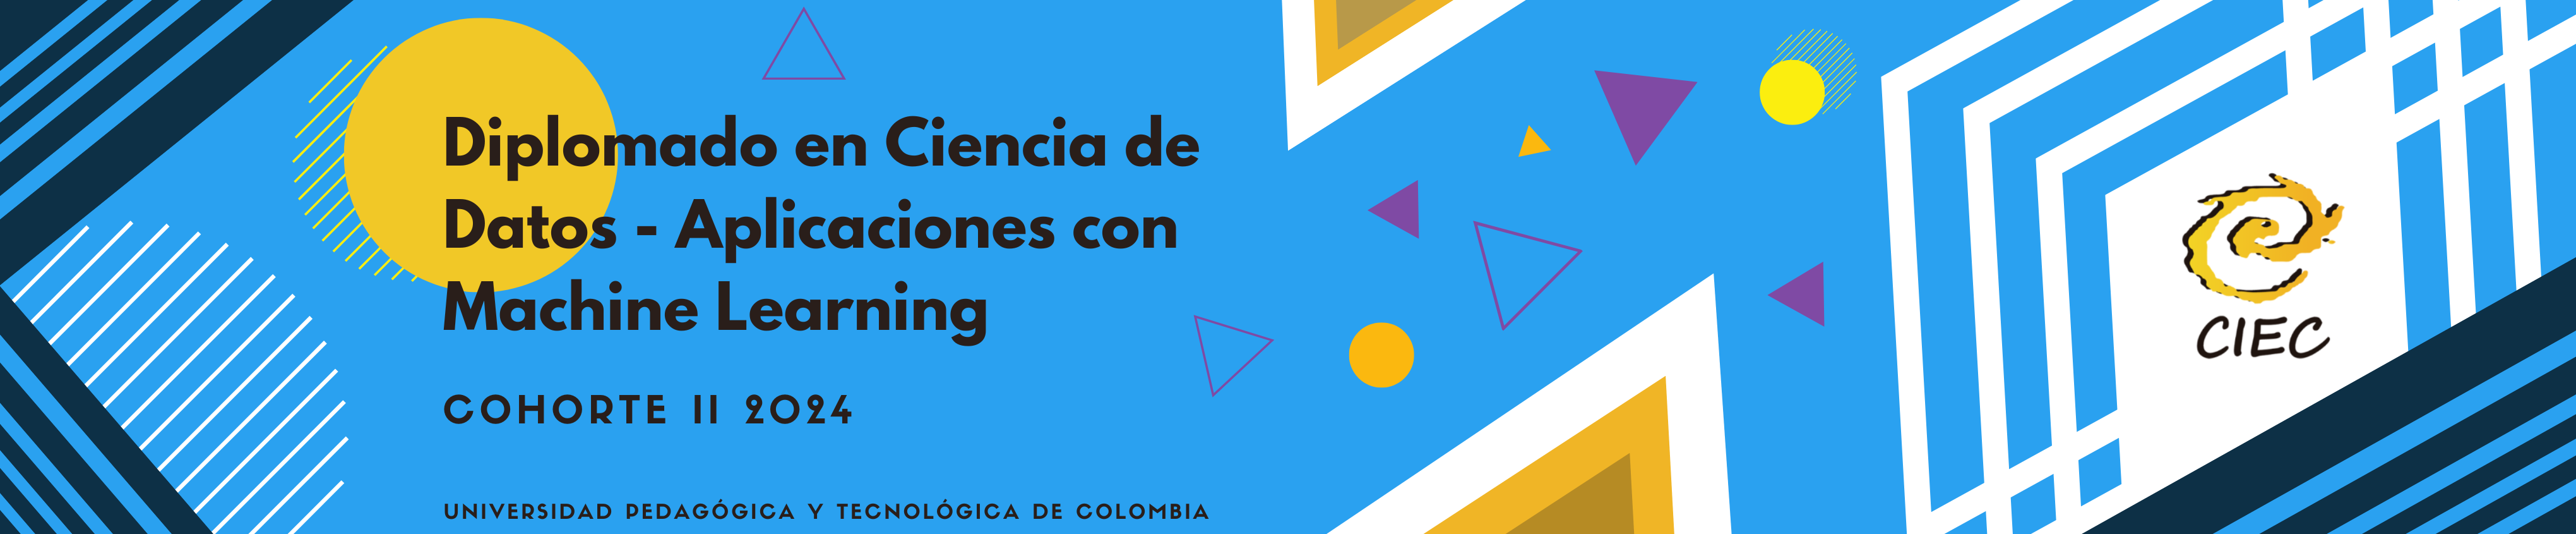

<!-- Main Title -->

**<h1 style="color: #FECB05; text-align: center;"> Módulo III: Proyecto 2 Análisis Exploratorio de Datos </h1>**


---

**<h2 style="color: #007ACC;">Autores</h2>**

- [Nicolás Castillo Ojeda](https://www.linkedin.com/in/nicolas-castillo-ak/)

---

**<h2 style="color: #007ACC;">Introducción</h2>**

Bienvenido al segundo proyecto guiado del curso de "*Análisis Esploratorio de Datos (EDA)*". Durante este proyecto, harémos uso de las herramientas de análisis exploratorio de datos vistas en clase y desarrollaremos un proyecto de EDA desde cero con base a un dataset de ejemplo en el cuál responderémos diferentes preguntas a cerca de nuestro conjunto de datos con base a las cinco fases básicas del proceso de EDA:

*   Detección de valores nulos y duplicados
*   Análisis univariado de variables numéricas
*   Análisis de variables categóricas
*   Análisis bivariado y de correlación
*   Análisis multivariado

En adición a lo anterior, realizaremos una serie de procedimientos de preprocesamiento de los datos dentro de los cuáles encontramos.

*  Numerización de variables categóricas
*  Imputación de valores nulos por medio del algoritmo KNN
*  Validación estadística de la inputación de valores
*  Balanceamiento de datos categóricos por oversampling y subsampling


---

**<h2 style="color: #007ACC;">Dependencias</h2>**

### <!-- Subsection 00 -->
**<h3 id="subsection00" style="color: #003366;">Librerías principales</h3>**

In [1]:
# Propósito general
import warnings
warnings.simplefilter(action='ignore')

# Manejo de datos
import numpy as np
import pandas as pd

# Visualización
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

# EDA
import missingno
import statsmodels.api as sm
from sklearn.impute import KNNImputer
import scipy.stats as sts
from scipy.stats import ks_2samp
from imblearn.over_sampling import SMOTE

# Preprocesamiento de datos
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, RobustScaler, MinMaxScaler
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, PolynomialFeatures

### <!-- Subsection 01 -->
**<h3 id="subsection01" style="color: #003366;">Utilerias</h3>**

In [ ]:
# Extensión de pandas
!pip install upsetplot

In [ ]:
# Instalación de Imbalanced-Learn
!pip install imblearn

In [ ]:
# Instalación de missingno
!pip install missingno

In [2]:
#--------------------------------------------------------------------------------
#--------------------------------- Histogram-Box --------------------------------
#--------------------------------------------------------------------------------

def histogram_box(dataframe, variable):
  df = dataframe
  fig, ax = plt.subplots(1,2,figsize=(14,5))
  # histogram_box plot
  sns.histplot(data=df, x=str(variable), kde=True, ax=ax[0])
  sns.boxplot(data=df, x=str(variable))
  # mean
  mean = df[str(variable)].mean()
  ax[0].axvline(mean, color='red')
  # stats-box
  variance = round(df[str(variable)].var(),2)
  kurtosis = round(df[str(variable)].kurt(),2)
  skewness = round(df[str(variable)].skew(),2)

  textstr = '\n'.join( (r'mean=%.2f' % (mean, ), r'Variance=%.2f' % (variance, ), r'Kurtosis=%.2f' % (kurtosis, ), r'Skewness=%.2f' % (skewness, )) )
  props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)
  ax[0].text(0.05, 0.95, textstr, transform=ax[0].transAxes, fontsize=10,
             verticalalignment='top', bbox=props)
  ax[0].set_title(f'Histogram of {variable}')
  ax[0].set_xlabel(f'{variable}')
  ax[0].set_ylabel("Frecuency")
  ax[0].grid(True)
  ax[1].set_title(f'Boxplot of {variable}')
  ax[1].set_xlabel(f'{variable}')
  ax[1].set_ylabel("Frecuencias")
  ax[1].grid(True)

  plt.subplots_adjust(hspace=0.5)
  plt.show()


#--------------------------------------------------------------------------------
#-------------------------- Percentage of null data -----------------------------
#--------------------------------------------------------------------------------

class data_processing:
  def __init__(self):
    pass

  # Percentage of null values
  def null_classifier(self,dataframe):
    series = dataframe.isnull().sum() * 100 / dataframe.shape[0]
    nulls  = {'Variable': series.index, 'Percentage of null values': series.values}
    nulls = pd.DataFrame(nulls).sort_values(by = 'Percentage of null values', ascending = False)
    return nulls

  # Simple column selector
  def column_selector(self, dataframe, column_names):
    df = dataframe
    selected_columns = [col for col in column_names if col in df.columns]
    selected_df = df[selected_columns]
    return selected_df

  # Column selector by null percentage
  def null_df_filter(self, dataframe, threshold):
    df = dataframe
    nulls = self.null_classifier(df)
    filtered = nulls[nulls['Percentage of null values'] < threshold]['Variable']
    df_filtered = df[filtered]
    return df_filtered

#--------------------------------------------------------------------------------
#----------------------------- Test de imputación -------------------------------
#--------------------------------------------------------------------------------

def imputation_test(original_dataframe, imputed_dataframe, problematic_columns):
  df_before = original_dataframe
  df_after = imputed_dataframe
  statistics = pd.DataFrame({})
  statistics['Item'] = ['t-test', 'p-value', 'ks_test', 'p_value_ks','observed mean', 'imputed mean','observed variance', 'imputed variance', 'mean difference', 'var difference']

  for column in problematic_columns:
    observed_values = df_before[column].dropna()
    imputed_values = df_after[column].dropna()

    mean_observed = observed_values.mean()
    mean_imputed = imputed_values.mean()
    var_observed = observed_values.var()
    imp_observed = imputed_values.var()
    var_difference = abs(var_observed - imp_observed)
    mean_difference = abs(mean_observed - mean_imputed)


    # two-sided t-test
    t_stat, p_value = sts.ttest_ind(observed_values, imputed_values, equal_var = False)
    # ks-test
    ks_stat, p_value_ks = ks_2samp(observed_values, imputed_values)
    statistics[column] = [t_stat, p_value, ks_stat, p_value_ks ,mean_observed, mean_imputed, var_observed, imp_observed, mean_difference, var_difference]


  return statistics


#--------------------------------------------------------------------------------
#------------------------ Visualizaciones especiales ----------------------------
#--------------------------------------------------------------------------------

class plots:
    def __init__(self):
         pass

    def histogram_box(self, dataframe, variable):
         df = dataframe
         fig, ax = plt.subplots(1,2,figsize=(14,5))

         # histogram_box plot
         sns.histplot(data=df, x=str(variable), kde=True, ax=ax[0])
         sns.boxplot(data=df, x=str(variable))

         # mean
         mean = df[str(variable)].mean()
         ax[0].axvline(mean, color='red')

         # stats-box
         variance = round(df[str(variable)].var(),2)
         kurtosis = round(df[str(variable)].kurt(),2)
         skewness = round(df[str(variable)].skew(),2)

         textstr = '\n'.join( (r'mean=%.2f' % (mean, ), r'Variance=%.2f' % (variance, ), r'Kurtosis=%.2f' % (kurtosis, ), r'Skewness=%.2f' % (skewness, )) )
         props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)
         ax[0].text(0.05, 0.95, textstr, transform=ax[0].transAxes, fontsize=10,
                    verticalalignment='top', bbox=props)
         ax[0].set_title(f'Histogram of {variable}')

         ax[0].set_xlabel(f'{variable}')
         ax[0].set_ylabel("Frecuency")
         ax[0].grid(True)
         ax[1].set_title(f'Boxplot of {variable}')
         ax[1].set_xlabel(f'{variable}')
         ax[1].set_ylabel("Frecuencias")
         ax[1].grid(True)

         plt.subplots_adjust(hspace=0.5)

         plt.show()


#--------------------------------------------------------------------------------
#--------------------- Plot de validación de imputación -------------------------
#--------------------------------------------------------------------------------

class inputation_plots:

  def __init__(self):
    pass

  def plot_inputation_comparison(self, observed_df, imputed_df, problematic_columns, subplot_layout, size):
    rows, cols = subplot_layout
    r, c = rows, cols
    fig, axs = plt.subplots(rows,cols, figsize = size)

    def plot_function(position,obs_val, imp_val, col_name, x_limits):
      mean_obs = np.mean(obs_val)
      mean_imp = np.mean(imp_val)
      i , j = position[0] , position[1]
      ax = axs[i,j]
      sns.histplot(observed_values, label='Original',kde=True, color='blue', ax=ax)
      sns.histplot(imputed_values, label='Imputed',kde=True, color='orange', ax=ax)
      ax.axvline(mean_obs, color='black')
      ax.axvline(mean_imp, color='red')
      ax.set_title(f'Comparison for {column}')
      ax.set_xlabel(f'{column}')
      ax.set_ylabel('Frequency')
      ax.grid(True)
      ax.set_xlim(x_limits[0], x_limits[1])
      ax.legend()

    for k, column in enumerate(problematic_columns):

      observed_values = observed_df[column].dropna()
      imputed_values = imputed_df[column].dropna()
      limits = [min(observed_values.min(),imputed_values.min()),
                max(observed_values.max(),imputed_values.max())]

      i = rows - r
      j = cols - c

      plot_function([i,j], observed_values, imputed_values, column, limits)
      c -= 1
      if c > 0:
        r = r
      else:
        r -= 1
        c = cols

    plt.show()

# <!-- Section 1 -->
**<h2 id="section1" style="color: #007ACC;">1. Importación de datos</h2>**

### <!-- Subsection 1.1 -->
**<h3 id="subsection11" style="color: #003366;">1.1. Importación y descripción de los datos</h3>**

---
Importación y descripción de los datos

---

El diccionario de los datos es el siguiente:

|Variable|Descripción|Tipología|
|---|---|---|
|PH| Indicador el estado ácido o alcalino del agua. Límite máximo permitido por la OMS es de 6.5 a 8.5|numérica|
|Dureza|Cantidad de sales de calcio y magnecio.|numérica|
|Sólidos|Sólidos totales disueltos (TDS). Es el parámetro más importante para el uso del agua, un alto valor indica alta mineralización. El límite deseable de TDS es de 500 mg/l y el límite máximo es de 1000 mg/l.|numérica|
|Cloraminas|Niveles de cloro y cloramina en el agua. Los valores hasta 4 miligramos por litro (4 partes por millón (ppm)) se consideran seguros en el agua potable.|numérica|
|Sulfatos|Niveles de sulfato, en la mayoría de los suministros de agua dulce, oscila entre 3 y 30 mg/l.|numérico|
|Coductividad|Concentración iónica en el agua determinada por la cantidad de sólidos disueltos en el agua. La CE (Conductividad Eléctrica) no debe superar los 400 micS/cm|numérico|
|Carbono_organico|Carbono Orgánico Total (COT), es la cantidad total de compuestos de carbono orgánico en el agua pura. |numérico|
|Trihalometanos|Los Trihalometanos (THM) son sustancias químicas que pueden encontrarse en el agua tratada con cloro. La concentración de THM en el agua potable varía según el nivel de materia orgánica en el agua, la cantidad de cloro necesaria para tratar el agua y la temperatura del agua que se está tratando. Los niveles de THM de hasta 80 ppm se considera seguros en el agua potable.|numérico|
|Turbidez|De pende de la cantidad de materia sólida presente en estado de suspensión. Es una medida de las propiedades de emisión de luz del agua y la prueba se utiliza para indicar la calidad de los vertidos con respecto a la materia coloidal.  El valor medio de turbidez obtenido para el Campus Wondo Gener es de 0.98 NTU e inferior al recomendado por la OMS dado por 5.00 NTU|categórica|


In [3]:
# Importación de los datos
path = 'https://raw.githubusercontent.com/AsorKy/Datasets/main/water_data.xlsx'
df_raw = pd.read_excel(path, sheet_name='in')
print('Dimensiones de los datos=', df_raw.shape)

Dimensiones de los datos= (3276, 10)


In [4]:
# Vista preliminar de los datos
df_raw.head()

,pH,Dureza,Sólidos,Cloraminas,Sulfatos,Conductividad,Carbono_orgánico,Trihalometanos,Turbidez,Potabilidad
0,NaN,204.89,20791.32,7.30,368.52,564.31,10.38,86.99,2.96,NO
1,3.72,129.42,18630.06,6.64,NaN,592.89,15.18,56.33,4.50,NO
2,8.10,224.24,19909.54,9.28,NaN,418.61,16.87,66.42,3.06,NO
3,8.32,214.37,22018.42,8.06,356.89,363.27,18.44,100.34,4.63,NO
4,9.09,181.10,17978.99,6.55,310.14,398.41,11.56,32.00,4.08,NO


Descripción de las variables del dataset.

In [5]:
# Tipos de variables en el dataset
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   pH                2785 non-null   float64
 1   Dureza            3276 non-null   float64
 2   Sólidos           3276 non-null   float64
 3   Cloraminas        3276 non-null   float64
 4   Sulfatos          2495 non-null   float64
 5   Conductividad     3276 non-null   float64
 6   Carbono_orgánico  3276 non-null   float64
 7   Trihalometanos    3114 non-null   float64
 8   Turbidez          3276 non-null   float64
 9   Potabilidad       3276 non-null   object 
dtypes: float64(9), object(1)
memory usage: 256.1+ KB


La información anterior, nos permite reconocer que de las diez variables que conformal al dataset, nueve de ellas son de tipo numérico y solo una, la potabilidad, es de tipo categórico.

# <!-- Section 1 -->
**<h2 id="section1" style="color: #007ACC;">2. Análisis Exploratorio de Datos  (EDA)</h2>**

### <!-- Subsection 2.1 -->
**<h3 id="subsection21" style="color: #003366;">2.1. Detección de valores nulos y duplicados</h3>**

---
Detección de valores nulos y duplicados

---


Una vez nos hemos asegurado que la carga de los datos ha sido exitosa y no parece haber errores de formato aparentes, procedemos a explorar los datos mediante visualizaciones y estadísticos principales. Para empezar, observemos la estadística descriptiva básica de nuestros datos numéricos y categóricos.

In [6]:
# Descripción estadística inicial de los datos numéricos
df = df_raw.copy()
df.describe()

,pH,Dureza,Sólidos,Cloraminas,Sulfatos,Conductividad,Carbono_orgánico,Trihalometanos,Turbidez
count,2785.000000,3276.000000,3276.000000,3276.000000,2495.000000,3276.000000,3276.000000,3114.000000,3276.000000
mean,7.080804,196.369481,22014.092415,7.122241,333.775784,426.205171,14.284921,66.396281,3.966731
std,1.594369,32.879680,8768.570852,1.583143,41.416864,80.824123,3.308232,16.174983,0.780354
min,0.000000,47.430000,320.940000,0.350000,129.000000,181.480000,2.200000,0.740000,1.450000
25%,6.090000,176.847500,15666.687500,6.130000,307.695000,365.735000,12.070000,55.847500,3.440000
50%,7.040000,196.965000,20927.830000,7.130000,333.070000,421.885000,14.220000,66.620000,3.955000
75%,8.060000,216.670000,27332.760000,8.112500,359.950000,481.790000,16.560000,77.337500,4.500000
max,14.000000,323.120000,61227.200000,13.130000,481.030000,753.340000,28.300000,124.000000,6.740000


De los estadísticos principales podemos observar:
* Gracias a que la cantidad de regístros es 3276, y a que vemos que variables como el pH solo regístran 2785 regístros, empezamos a intuir que exísten valores faltantes dentro de nuestro conjunto de datos.

* En promedio, el pH de las muestras tomadas se encuentran dentro del rango aceptado  (6.5 - 8.5), no obstante, vemos que métricas como el Q3 y el valor máximo, se encuentran muy por encima de lo considerado como potable. Así pues, solo hasta el Q2 (mediana) de las muestras se encuentran dentro del rango potable.

* En promedio, los valores de sólidos se encuentran muy por encima (el doble) de lo considerado como aceptable. Vemos que en general las muéstras de agua contienen altos contenidos de sólidos ya que incluso desde el Q1, todos los valores de los cuartiles superan el rango aceptado, el cuál, según el diccionario de los datos, se encuentra entre 500 mg/l y 1000 mg/l.

* En general, tanto el valor promedio como los los tres cuartiles del nivel de cloraminas se encuentra muy por encima de lo aceptado, el cuál según el diccionario de los datos, corresponde a 4ppm.

* En general, tanto el valor promedio como los los tres cuartiles del nivel de sulfatos se encuentra muy por encima de lo aceptado, el cuál según el diccionario de los datos, corresponde a 30 mg/l.

* En cuanto a la Conductividad, el promedio se encuentra un poco por encima de lo aceptado como potable, y en general, los datos contienen una alta conductividad. Esto se evidencia ya que solo hasta el Q1 los datos poseen un valor de conductividad aceptable.

* En general, los Trihalometanos se encuentran por debajo del límite el cuál según el diccionario de los datos, corresponde a 80 ppm. Podemos evidenciarlo a partir de los estadísticos principales ya que tanto el promedio, como los datos hasta el Q3 se encuentran por debajo del límite.

* Con respecto a la turbidez, en general los datos se encuentran dentro del rango permitído por la OMS (5 NTU) pero solo hasta antes del Q1, los datos poseen el nivel de turbidez aceptable según el CWG.


Una vez hemos estudiado de manera general los datos numéricos, el análisis inicial de los datos categóricos nos dice que los datos no están balanceados y que es la categoría ```NO``` es la clasificación de potabilidad predominante. Conclusión que es tambíen deducida a partir de los estadísticos principales de las variables numéricas. Esto nos dice que solo el 60% de los datos registrados corresponden a muestras de aguas NO potables.



In [7]:
# Descripción estadística inicial de datos categóricos
df.describe(include='object')

,Potabilidad
count,3276
unique,2
top,NO
freq,1998


No obstante, ¿estas observaciones iniciales son acertadas?. Para contestar ésta pregunta, tenemos que determinar si dentro del dataset exísten valores nulos por columna para descartar la posibilidad de que nuestras observaciones estén sesgadas debido a la presencia de valores ausentes.


In [8]:
# Número de valores nulos por columna
tot = len(df)
nulos = (df.isnull().sum()/tot) * 100
nulidad = pd.DataFrame({'Variable': nulos.index, 'Porcentaje de nulidad':nulos.values})
nulidad

,Variable,Porcentaje de nulidad
0,pH,14.987790
1,Dureza,0.000000
2,Sólidos,0.000000
3,Cloraminas,0.000000
4,Sulfatos,23.840049
5,Conductividad,0.000000
6,Carbono_orgánico,0.000000
7,Trihalometanos,4.945055
8,Turbidez,0.000000
9,Potabilidad,0.000000


Al encontrar el número de valores nulos y determinar el porcentaje de nulidad (porcentaje de datos nulos), vemos que tenemos tres variables con presencia de valores nulos, donde de mayor a menor cantidad de nulidad se tiene las siguientes variables:

1. Sulfatos
2. pH
3. Trihalometanos

Dentro del conocimiento del autor del presente proyecto, es conocido que humbrales tales como 30% y 40% de nulidad son suficientes para considerar descartar una variable según el contexto del problema en cuestión. Con base a esto, ya que todas las variables con valores nulos no sobrepasan el humbral del 30%, conservaremos todas las variables problemáticas y procederemos más adelante a emplear técnicas de imputación de datos.

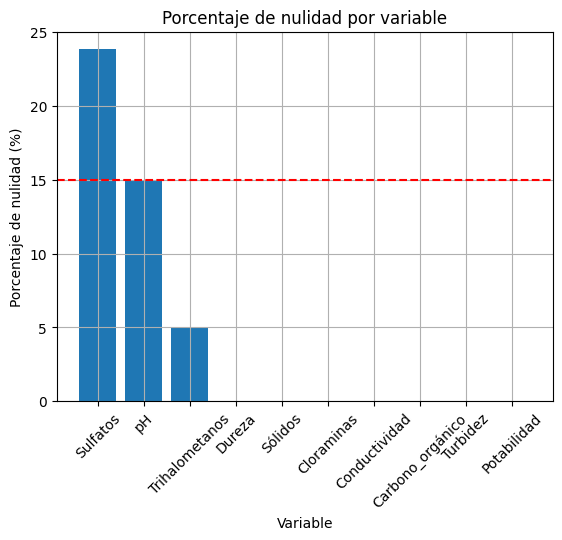

In [9]:
# Grafico de barras del porcentaje de nulidad
nulidad = nulidad.sort_values(by='Porcentaje de nulidad', ascending=False)

plt.bar(nulidad['Variable'], nulidad['Porcentaje de nulidad'])
plt.axhline(y=15, color='red', linestyle='dashed', label='Threshold')
plt.xlabel('Variable')
plt.ylabel('Porcentaje de nulidad (%)')
plt.title('Porcentaje de nulidad por variable')
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

Ahora, procedemos a responder la pregunta ¿exíste un número importante de duplicados?. La respuesta a esta pregunta es NO exísten regístros duplicados dentro de nuestros datos.

In [10]:
# Numero de duplicados
n_duplicados = df.duplicated().sum()
porcentaje_duplicados = (n_duplicados / df.shape[0]) *100
print('El número de duplicados es = ', n_duplicados)
print('Porcentaje de duplicados es =', porcentaje_duplicados)

El número de duplicados es =  0
Porcentaje de duplicados es = 0.0


### <!-- Subsection 2.2 -->
**<h3 id="subsection22" style="color: #003366;">2.2. Preprocesamiento de los datos</h3>**

##### <!-- Subsection 2.2.1 -->
**<h3 id="subsection221" style="color: #003366;">2.2.1. Transformación de variables categóricas</h3>**

---
Transformación de variables categóricas

---

Antes de realizar la imputación de los datos, es necesrio convertir las variables categóricas a numéricas. Para ello, emplearemos la estrategia one-hot-encoder ya que la ventaja de esta transformación es que no establece una jerarquía implicita a la conversión como si ocurre en el OrdinalEncoder. A demás, este acercamiento es apropiado debido a que solo necesitamos convertir una sola variable categórica binaria, lo que significa que al realizar la transformación OneHot no agregaríamos ninguna dimensión extra a nuestros datos ni una relación ordinal, ya que al ser Potabilidad una variable categórica binaria, bastaría con realizar la transformación `SI -> 1` y `NO -> 0`.

In [11]:
# One hot encoder
df_enc = df.copy()
df_enc['Potabilidad'] = df_enc['Potabilidad'].map({'SI':1,'NO':0})
df_enc.head()

,pH,Dureza,Sólidos,Cloraminas,Sulfatos,Conductividad,Carbono_orgánico,Trihalometanos,Turbidez,Potabilidad
0,NaN,204.89,20791.32,7.30,368.52,564.31,10.38,86.99,2.96,0
1,3.72,129.42,18630.06,6.64,NaN,592.89,15.18,56.33,4.50,0
2,8.10,224.24,19909.54,9.28,NaN,418.61,16.87,66.42,3.06,0
3,8.32,214.37,22018.42,8.06,356.89,363.27,18.44,100.34,4.63,0
4,9.09,181.10,17978.99,6.55,310.14,398.41,11.56,32.00,4.08,0


Dentro de las técnicas de numerización de datos encontramos entonces dos acercamientos principales, **One-Hot Encoding** y **Ordinal Encoding**.

##### **One-Hot Encoding**

El **One-Hot Encoding** es una técnica que convierte una variable **categórica nominal** en un conjunto de variables binarias. Cada categoría única de la variable original se representa como una nueva columna, que toma el valor de 1 si la observación pertenece a esa categoría y 0 si no. Por ejemplo, si suponemos que exíste una variable categórica "Color" con los valores `["Rojo", "Verde", "Azul"]`. Después de aplicar One-Hot Encoding, se generarán tres columnas: una para "Rojo", otra para "Verde", y otra para "Azul".

| Color   | Rojo | Verde | Azul |
|---------|------|-------|------|
| Rojo    |  1   |   0   |  0   |
| Verde   |  0   |   1   |  0   |
| Azul    |  0   |   0   |  1   |

Algunas de sus ventajas son:

1. **No introduce relaciones de orden**: A diferencia del ordinal encoding, One-Hot Encoding no implica ninguna relación jerárquica entre las categorías, lo cual es adecuado para datos categóricos nominales (sin orden natural).
2. **Fácil de interpretar**: Cada columna representa de manera clara si una observación pertenece a una categoría específica.
3. **Adecuado para algoritmos basados en distancias**: En algoritmos como **K-Nearest Neighbors** y **KMeans**, donde las distancias o las similitudes entre las características son importantes, el One-Hot Encoding evita que las diferencias numéricas falsas (debido al orden) afecten los cálculos.

algúnas de sus desventajas son:
1. **Incremento dimensional**: Si una variable categórica tiene muchas categorías, el número de columnas en el dataset puede aumentar de manera significativa. Esto lleva al **problema de la alta dimensionalidad**, que puede hacer que los modelos sean más lentos y difíciles de interpretar.
2. **Redundancia**: Para $n$ categorías, se generan n nuevas columnas. Sin embargo, esto genera redundancia porque solo $n-1$ columnas son necesarias para representar la información. Una categoría puede deducirse de las demás.



##### **Ordinal Encoding**

El **Ordinal Encoding** es una técnica que asigna un valor numérico entero a cada categoría de una **variable ordinal**. Aquí, las categorías se representan por un número basado en su posición en un orden predefinido. Este método es adecuado solo para datos ordinales, donde las categorías tienen un orden o jerarquía natural. Por ejemplo, si tenemos una variable categórica "Tamaño" con valores `["Pequeño", "Mediano", "Grande"]`, se puede asignar el valor 1 a "Pequeño", el valor 2 a "Mediano", y el valor 3 a "Grande".

| Tamaño   | Valor |
|----------|-------|
| Pequeño  |   1   |
| Mediano  |   2   |
| Grande   |   3   |

Algúnas de sus ventajas son:

1. **Eficiencia en almacenamiento**: En comparación con el One-Hot Encoding, el Ordinal Encoding no aumenta la dimensionalidad, ya que solo añade una columna por cada variable categórica.
2. **Representa un orden natural**: Este método es perfecto para variables ordinales donde las categorías tienen un significado en cuanto a orden (p. ej., calificaciones de satisfacción, niveles de educación, etc).

Algúnas de sus desventajas son:

1. **Introduce una relación de orden**: Si las categorías no tienen un orden inherente, como ocurre con las variables nominales, el Ordinal Encoding puede introducir falsas relaciones jerárquicas entre las categorías, lo que puede sesgar los resultados del modelo.
2. **Inadecuado para algoritmos basados en distancia**: Algoritmos como **K-NN** o **regresión lineal** pueden malinterpretar las diferencias numéricas como distancias significativas entre categorías, lo que podría llevar a un rendimiento pobre.

#### **Casos oportunos de uso**:
- **Variables ordinales**: Cuando las categorías tienen un orden natural (p. ej., calificación de productos: "Bajo", "Medio", "Alto").
- **Modelos de regresión o árboles de decisión**: Algoritmos que no dependen de distancias pueden utilizar Ordinal Encoding sin problemas, siempre que las categorías sean ordenadas.

##### **Comparación de One-Hot Encoding y Ordinal Encoding**

| Característica          | One-Hot Encoding                                   | Ordinal Encoding                                |
|-------------------------|----------------------------------------------------|-------------------------------------------------|
| **Tipo de variable**     | Nominal (sin orden)                               | Ordinal (con orden)                             |
| **Dimensionalidad**      | Incrementa el número de columnas (nueva columna por cada categoría) | Mantiene la dimensionalidad (una columna por variable) |
| **Relación entre categorías** | No introduce relaciones de orden                  | Introduce una relación de orden (puede ser falsa) |
| **Impacto en modelos**   | Adecuado para algoritmos basados en distancia y regresión | Puede sesgar modelos basados en distancia si las categorías no tienen un orden real |
| **Escalabilidad**        | Se vuelve ineficiente con muchas categorías        | Escalable, pero solo útil si hay un orden claro |

Se emplea un acercamiento One-Hot Encoding cuando:
- Cuando las categorías no tienen un orden natural.
- Cuando se utilizan modelos sensibles a las magnitudes y distancias, como **SVM**, **K-NN**, y **regresión logística**.
- Si hay pocas categorías y no se espera un gran aumento en la dimensionalidad.

Se emplea un acercamiento  Ordinal Encoding cuando:
- Cuando las categorías tienen un orden natural.
- Para variables que representen clasificaciones o niveles de progresión (e.g., encuestas de satisfacción).
- En algoritmos que no son sensibles a la distancia entre valores numéricos, como **árboles de decisión** y **bosques aleatorios**.



In [45]:
# Ejemplo de codificación Dummy

# Creamos un DataFrame de ejemplo
data = {
    'Color': ['Rojo', 'Verde', 'Azul', 'Verde', 'Rojo'],
    'Tamaño': ['Pequeño', 'Grande', 'Pequeño', 'Mediano', 'Grande']
}

df_ex = pd.DataFrame(data)

# Aplicamos codificación dummy
df_dummy = pd.get_dummies(df_ex , columns=['Color'], drop_first=False)*1
df_dummy

,Tamaño,Color_Azul,Color_Rojo,Color_Verde
0,Pequeño,0,1,0
1,Grande,0,0,1
2,Pequeño,1,0,0
3,Mediano,0,0,1
4,Grande,0,1,0


In [46]:
# Importación de  un codificador one-hot
from sklearn.preprocessing import OneHotEncoder

# Creamos un DataFrame de ejemplo
data = {
    'Color': ['Rojo', 'Verde', 'Azul', 'Verde', 'Rojo'],
    'Tamaño': ['Pequeño', 'Grande', 'Pequeño', 'Mediano', 'Grande']
}

df_ex  = pd.DataFrame(data)

# Inicializamos el codificador OneHotEncoder
encoder = OneHotEncoder()

# Aplicamos la codificación One-Hot (convertimos la matriz dispersa a densa con .toarray())
one_hot_encoded = encoder.fit_transform(df_ex [['Color']]).toarray()

# Creamos un nuevo DataFrame con las columnas codificadas
one_hot_df = pd.DataFrame(one_hot_encoded, columns=encoder.get_feature_names_out(['Color']))

# Concatenamos el DataFrame original con el DataFrame codificado
df_one_hot = pd.concat([df_ex , one_hot_df], axis=1).drop('Color', axis=1)

# Mostrar el resultado
df_one_hot

,Tamaño,Color_Azul,Color_Rojo,Color_Verde
0,Pequeño,0.0,1.0,0.0
1,Grande,0.0,0.0,1.0
2,Pequeño,1.0,0.0,0.0
3,Mediano,0.0,0.0,1.0
4,Grande,0.0,1.0,0.0


In [47]:
# Importación de  un codificador ordinal encoder
from sklearn.preprocessing import OrdinalEncoder

# Creamos un DataFrame de ejemplo
data = {
    'Tamaño': ['Pequeño', 'Grande', 'Mediano', 'Grande', 'Pequeño']
}

df_ex  = pd.DataFrame(data)

# Inicializamos el codificador OrdinalEncoder
ordinal_encoder = OrdinalEncoder(categories=[['Pequeño', 'Mediano', 'Grande']])

# Aplicamos la codificación ordinal
df_ex ['Tamaño_Codificado'] = ordinal_encoder.fit_transform(df[['Tamaño']])
df_ex

,Tamaño,Tamaño_Codificado
0,Pequeño,0.0
1,Grande,2.0
2,Mediano,1.0
3,Grande,2.0
4,Pequeño,0.0


##### <!-- Subsection 2.2.2 -->
**<h3 id="subsection2212" style="color: #003366;">2.2.2. Imputación de valores nulos</h3>**

---
Imputación de valores nulos

---

Una vez hemos realizado la numerización de los datos, procederémos a manejar los datos nulos mediante técnicas de imputación por modelos. Ésto debido a que en primer lugar, las variables categóricas del problema no presentan ausencias así que no será necesario emplear técnicas como imputación por el más frecuente. Más aún, técnicas como imputación por promedio en los datos numéricos no suelen ser demasiado realistas.
Así pues, en la presente sección emplearemos la técnica de imputación por medio del modelo KNN regresor de modo tal que los valores a imputar serán deducidos a partir de la similaridad del regístro con otros regístros en el dataset.
Por defecto, el imputador KNN emplea los 5 regístros mas similares para imputar los valores en las columnas donde exísten ausencias.

In [12]:
# Función de imputación por algoritmo KNN
from sklearn.impute import KNNImputer

def knn_imputator(dataframe):
  df = dataframe.copy()
  knn = KNNImputer()
  df = pd.DataFrame(knn.fit_transform(df), columns = df.columns)
  return df

In [13]:
# Imputación de valores por medio del algoritmo KNN
df_knn = knn_imputator(df_enc)
df_knn.head()

,pH,Dureza,Sólidos,Cloraminas,Sulfatos,Conductividad,Carbono_orgánico,Trihalometanos,Turbidez,Potabilidad
0,7.158,204.89,20791.32,7.30,368.520,564.31,10.38,86.99,2.96,0.0
1,3.720,129.42,18630.06,6.64,336.094,592.89,15.18,56.33,4.50,0.0
2,8.100,224.24,19909.54,9.28,330.450,418.61,16.87,66.42,3.06,0.0
3,8.320,214.37,22018.42,8.06,356.890,363.27,18.44,100.34,4.63,0.0
4,9.090,181.10,17978.99,6.55,310.140,398.41,11.56,32.00,4.08,0.0


Corroboramos a continuación que la imputación fué exitosa.

In [14]:
# Verificación de nulidad después de imputación de valores
df_knn.isnull().sum()

,0
pH,0
Dureza,0
Sólidos,0
Cloraminas,0
Sulfatos,0
Conductividad,0
Carbono_orgánico,0
Trihalometanos,0
Turbidez,0
Potabilidad,0


##### <!-- Subsection 2.2.3 -->
**<h3 id="subsection223" style="color: #003366;">2.2.3. Verificación de validez de la imputación</h3>**

---
Verificación de validez de la imputación

---

Una vez hemos realizado la imputación de los datos, realicemos un breve análisis para verificar que los datos no hayan cambiado sustancialmente después de la imputación y descartar que el método haya generado sesgos cambiando la distribución de los datos.

Para realizar el análisis visual, se emplea el constructor ```inputation_plots()```, el cual se encuentra dentro del notebook complementario al presente llamado ```visuals```, el cual nos permitirá comparar las distribuciones de las variables imputadas antes y después de la imputación.



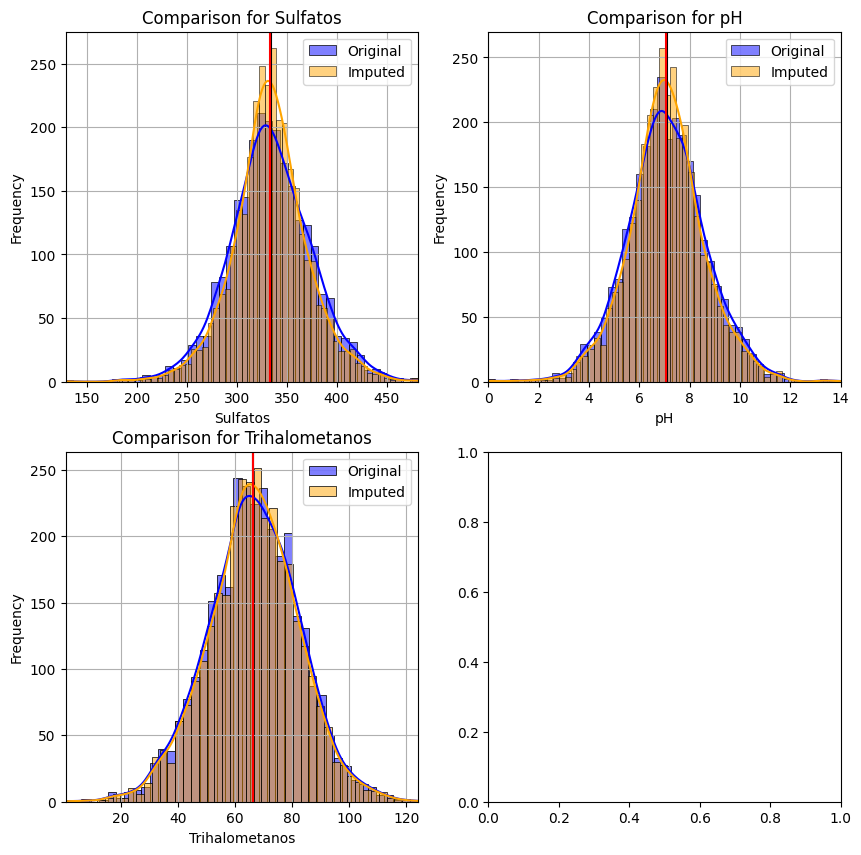

In [15]:
# Comparación de distribuciónes de las variables imputadas antes y después de la imputación
inputer_plot = inputation_plots()
problematic_columns = ['Sulfatos', 'pH', 'Trihalometanos']
inputer_plot.plot_inputation_comparison(df, df_knn, problematic_columns, (2,2), (10,10))

Vemos en los graficos anteriores que el método de imputación parece ser exitoso, ya que no cambia sustancialmente la distribución de los datos y éstas variables conservan su forma de distribución similar a una distribución normal. Note entonces que es para las variables "Sulfatos" y "pH" en donde más diferencias (aunque leves) exísten entre las distribuciones, lo cuál puede explicarse a que estas dos son las variables que más imputación necesitan, por ende, una mayor cantidad de regístros "artificiales" han sido ingresados a los datos aumentando el conteo de datos en la parte central de la distribución.

No obstante note que los promedios, simbolizados por las líneas verticales "roja" y "negra" respectivamente correspondientes a las distribuciones imputadas y originales, se alínean casi a la perfección y no se evidencia ningún corrimiento de la distribución imputada con respecto a la distribución original. La única leve diferencia entre ambas distribuciones es un mayor número de conteo de valores en la parte central de la distribución, haciendo que la distribución imputada se encuentre ligeramente por encima de la distribución original en la parte central de la campana.

Por otra parte, dentro de la sección de dependencias presente en el presente notebook, se encuentra la función `imputation_test` la cual es una función construida para ejecutar diferentes test estadísticos de testeo de hipotesis la cual usaremos a continuación para determinar si las distribuciones antes y después de la imputación, presentan diferencias significativas. Para ello, tengamos en cuenta lo siguiente:

1. **Hipótesis Nula (H0)**: La hipótesis nula es que **no hay diferencia** significativa entre las distribuciones original e imputada, lo que significa que el método de imputación no introduce sesgo.

2. **Hipótesis Alternativa (H1)**: La hipótesis alternativa es que **hay una diferencia significativa** entre las distribuciones, lo que indica que el método de imputación introduce sesgo.

3. **Interpretación del p-value**: El p-value es la probabilidad de observar una diferencia tan grande o más grande entre las distribuciones original e imputada, si la hipótesis nula fuera verdadera. Por lo tanto, un p-value bajo indica que la diferencia observada es poco probable de haber ocurrido por casualidad bajo la hipótesis nula.

Si el p-value es menor que un nivel de significancia predefinido (por ejemplo, 0.05), entonces rechazamos la hipótesis nula y concluimos que hay evidencia suficiente para afirmar que hay una diferencia significativa entre las distribuciones. En este caso, podríamos decir que el método de imputación introduce sesgo.

Si el p-value es mayor que el nivel de significancia, no hay suficiente evidencia para rechazar la hipótesis nula. En este caso, no podemos concluir que el método de imputación introduce sesgo significativo en la distribución.

In [16]:
# Validación de hipótesis para imputación por knn
problematic_columns = ['Sulfatos', 'pH', 'Trihalometanos']
knn_test = imputation_test(df, df_knn, problematic_columns)
knn_test

,Item,Sulfatos,pH,Trihalometanos
0,t-test,0.160953,0.066108,-0.017275
1,p-value,0.872137,0.947294,0.986218
2,ks_test,0.043969,0.026596,0.011510
3,p_value_ks,0.008050,0.231939,0.981860
4,observed mean,333.775784,7.080804,66.396281
5,imputed mean,333.605774,7.078162,66.403204
6,observed variance,1715.356589,2.542014,261.630070
7,imputed variance,1402.732954,2.241844,250.833609
8,mean difference,0.170009,0.002642,0.006923
9,var difference,312.623635,0.300170,10.796461


Podemos observar de la tabla anterior que el p-value del t-test para las tres variables es superior a 0.05, por ende, el método de imputación por KNN es exitoso ya que no hay evidencia suficiente para concluir que exíste un sesgo introducido por la imputación.
Más aún, se evidencia que la diferencia de los promedios para los tres casos es casi nulo y la diferencia en las varianzas es pequeña, por ende, este método es adecuado para procesar los datos nulos.

### <!-- Subsection 2.3 -->
**<h3 id="subsection23" style="color: #003366;">2.3. Análisis univariado de variables numéricas</h3>**

---
Análisis de Variables numéricas

---

Ya que no exísten valores nulos en nuestras variables, procedemos con el análisis univariado de nuestro dataset. Para empezar, observemos las distribuciones de las variables numéricas contínuas y para la variable `'cnt'` e intentemos detectar posibles valores atípicos o outliers. Para ésto, emplearemos una visualización de histograma y boxplot mediante la función `histogram_box`, presente en la sección de utilidades del presente notebook.

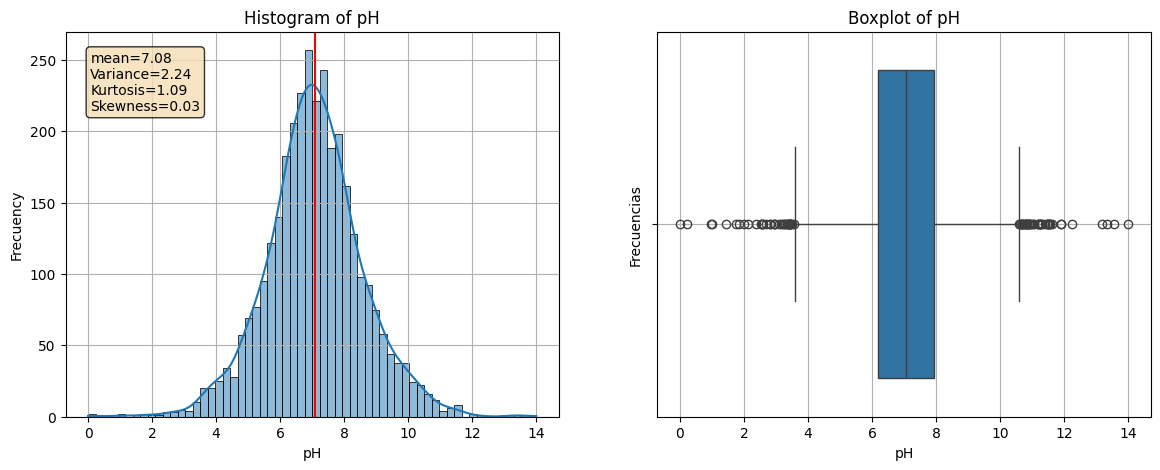

In [17]:
# Distribución (histograma) de la variable cantidad de Ph
histogram_box(df_knn, 'pH')

A partir de la visualizacion anterior, podemos observar lo siguiente:
* El comportamiento de la variable PH es muy similar a una distribución normal.
* El centro de los datos, su promedio y mediana, se encuentra justo en el centro del rango permitido de PH 6.5 - 8.5. Lo cual insinúa que la mayoría de datos posee un valor aceptable como potable y exíste una pequeña cantidad de datos con ph extremo hacia arriba o abajo, es decir, o muy alto o muy bajo.
* Exíste una cantidad considerable de valores atípicos pero que no es superior o comparable al conjunto de datos centrados en el valor promedio.
* Lo anterior nos indíca que exíste una candidad escasa de muestras de agua muy pura, y una cantidad escasa de muestras de agua altamente contaminadas.
* La distribución es simétrica, baja varianza y gran concentración al rededor del valor medio.

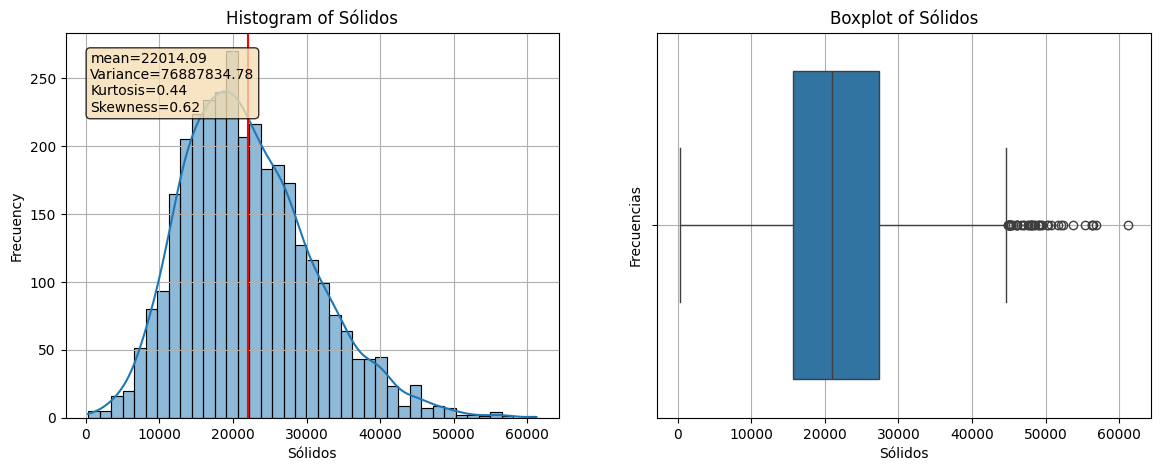

In [18]:
# Distribución (histograma) de la variable solidos
histogram_box(df_knn, 'Sólidos')

A partir de la visualizacion anterior, podemos observar lo siguiente:
* El comportamiento de la variable Solidos presenta un pequeño sesgo positivo, hacia la derecha.
* El promedio de los datos se encuentra por encima del valor recomendado de sólidos disueltos 500mg/l - 1000mg/l.
* Exíste una cantidad considerable de valores atípicos pero que no es superior o comparable al conjunto de datos centrados en el valor promedio hacia la derecha, es decir, exíste una cantidad de muestras de agua con una alta concentración de sólidos disueltos.
* La concentración de los valores es cercana a la concentración mesocurtica, es decir, los valores no estan fuertemente concentrados en un rango estrecho central de valores.


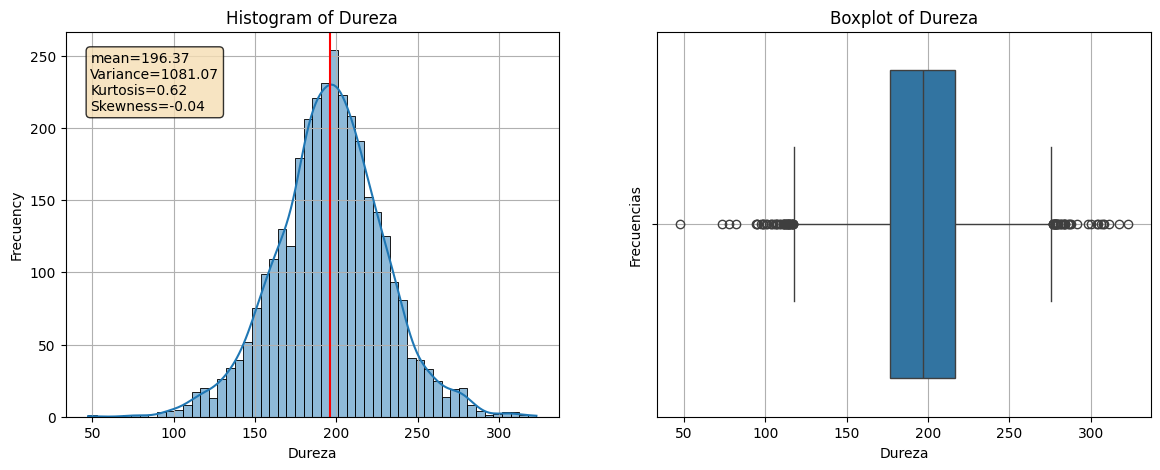

In [19]:
# Distribución (histograma) de la variable cantidad de dureza
histogram_box(df_knn, 'Dureza')

A partir de la visualizacion anterior, podemos observar lo siguiente:
* El comportamiento de la variable Dureza es muy similar a una distribución normal.
* Es demasiado probable encontrar muestras de agua con alto contenido de sales y magnesio.
* La distribución es simétrica, alta varianza y baja concentración al rededor del valor medio.
* La concentración de valores tiende a comportarse leptocurticamente, es decir, exíste una gran cantidad de datos cuyos valores se encuentran en torno a un rango estrecho de valores centrados en el promedio de los datos.

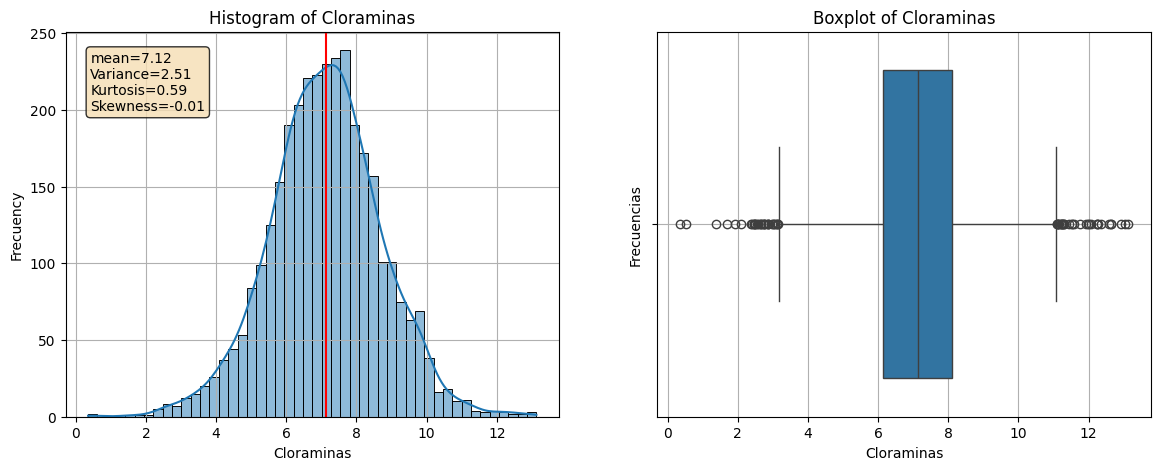

In [20]:
# Distribución (histograma) de la variable cantidad de Cloraminas
histogram_box(df_knn, 'Cloraminas')

A partir de la visualizacion anterior, podemos observar lo siguiente:
* El comportamiento de la variable Cloraminas es muy similar a una distribución normal.
* Se puede observar que la distribución se encuentra centrada entre 6 y 8, niveles superiores al nivel de cloramina considerado como seguro. Esto quiere decir que la mayoría de los datos se encuentran al rededor de valores NO seguros de cloro y cloraminas, por ende, es muy probable que las muestras de agua tomadas sean en su mayoría NO potables.
* Exíste una varianza pequeña en los datos y una kurtosis pequeña pero positiva, lo cual indica que la distribución tiende a tener una concentración leptocúrtica.

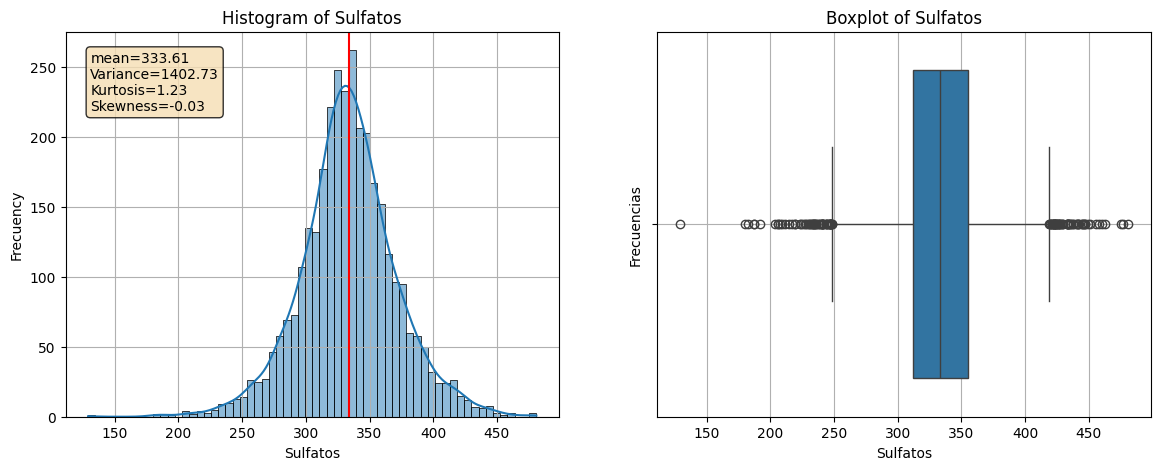

In [21]:
# Distribución (histograma) de la variable cantidad de Cloraminas
histogram_box(df_knn, 'Sulfatos')

A partir de la visualizacion anterior, podemos observar lo siguiente:
* El comportamiento de la variable Sulfatos es muy similar a una distribución normal.
* Se puede observar que la distribución se encuentra centrada en el valor de concentración de sulfatos igual a 333 mg/l, nivel inseguro o no apropiado de sulfato. En general, la concentración ideal de sulfato se encuentra entre 3 mg/l y 30 mg/l. No obstante el nivel seguro de concentración de sulfato es de 250 mg/l, por ende, esta variable nos dice que la gran mayoría de las muestras de agua son consideradas como NO potables.
* La distribución es leptocurtica, lo que indica que existe una marcada concentración de los valores en un rango estrecho al rededor del valor central de la distribución.

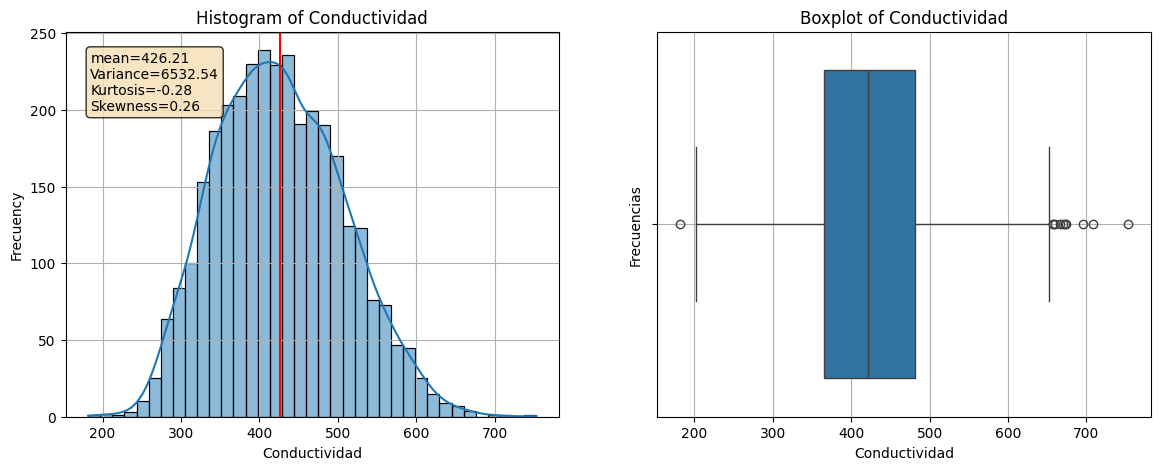

In [22]:
# Distribución (histograma) de la variable conductividad
histogram_box(df_knn, 'Conductividad')

A partir de la visualizacion anterior, podemos observar lo siguiente:
* El comportamiento de la variable Conductividad es muy similar a una distribución normal.
* Se puede observar que la distribución se encuentra centrada en el valor de conductividad de 426, valor ligeramente superor al valor límite de conductividad de agua potable, asi que a pesar de que la distribución presenta un leve sesgo positivo indicando que la mayor concentración de valores de conductividad se encuentra en valores bajos de conductividad, el bajo nivel de kurtosis el cual es mesocurtico, indica que exíste una concentración de valores en un rango amplio. Si observamos la distribución, podemos ver que la mayoria de valores se encuentra entre 300 y 500, valores altos y no aceptados. Por ende, se puede ver que la mayoría de las muestras NO son potables.


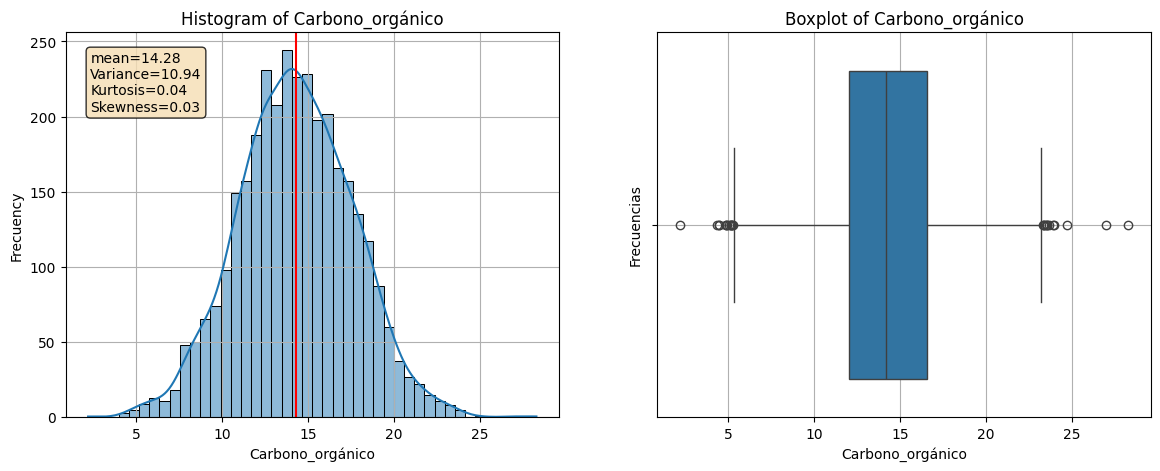

In [23]:
# Distribución (histograma) de la variable carbono orgánico
histogram_box(df_knn, 'Carbono_orgánico')

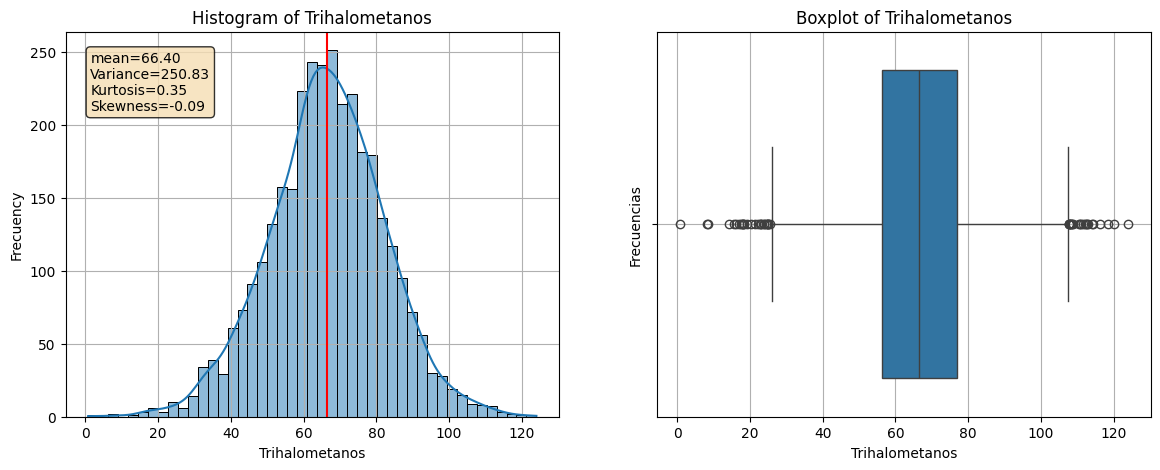

In [24]:
# Distribución (histograma) de la variable Trihalometanos
histogram_box(df_knn, 'Trihalometanos')

A partir de la visualizacion anterior, podemos observar lo siguiente:
* El comportamiento de la variable Thrihalometanos es muy similar a una distribución normal.
* Se puede observar que la distribución se encuentra centrada en el valor de concentración de 66, valor cercano al límite de aceptabilidad de concentración el cuál es 80. Esto nos indica que al ser una distribución con bajo kurtosis cercano a un nivel mesocúrtico, los valores de aceptabilidad de concentración se encuentran casi normalmente distribuidos, lo cual indica que exíste una gran cantidad de muestras que de acuerdo a esta variable, son potables, y una cantidad similar de muestras que no lo son. No obstante, las muestras potables corresponden a aguas de baja pureza.


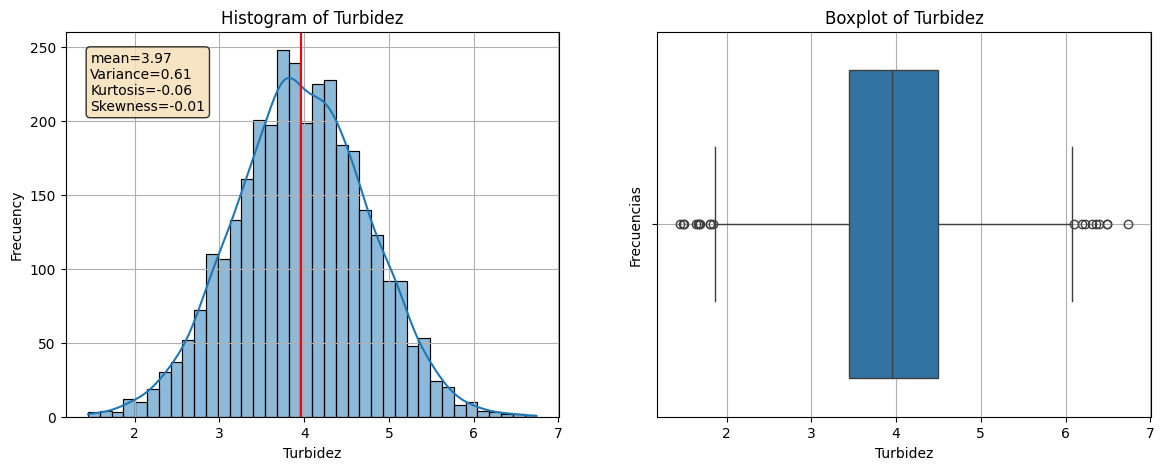

In [25]:
# Distribución (histograma) de la variable 'Turbidez'
histogram_box(df_knn, 'Turbidez')

A partir de la visualizacion anterior, podemos observar lo siguiente:
* El comportamiento de la variable Turbidez es muy similar a una distribución normal.
* Se puede observar que la distribución se encuentra centrada en el valor de turbidez se encuentra muy por encima de lo aceptado por el GWP y por dabajo de lo que la OMS recomienda. No obstante, la mayor parte de las muestras poseen un alto nivel de turbidez que limita con la impotabilidad del agua.

En general, a partir de las anteriores distribuciones podemos concluir lo siguiente:
1. Es muy probable encontrar que la mayoría de las muestras de agua sean consideradas como NO potables, ya que en general, la gran mayoría de muestras posee alta dureza, gran cantidad de sólidos, gran cantidad de sulfatos, alta conductividad, alta cantidad de Trihalomentanos y gran turbidez.
2. Todas las variables de nuestro dataset se comportan cercanamente a una distribución normal.
3. En general, las distribuciones posee un alto kurtosis lo cual permite que exísta una gran cantidad de outliers a ambos lados de las distribuciones.

### <!-- Subsection 2.4 -->
**<h3 id="subsection24" style="color: #003366;">2.4. Análisis de variables categóricas</h3>**


---
Análisis de variables categóricas

---

Una vez analizadas las variables numéricas no ordinales y contínuas, procedamos a analizar que ocurre con las variables categóricas binarias.
A partir del siguiente plot, podemos observar que el dataset esta desbalanceado con respecto a la variable "Potabilidad". Esto afirma las conclusiones deducidas en la sección anterior de analisis univariado, donde vímos que si observamos el comportamiento de cada variable y lo comparamos con los valores límite de aceptación, nos es posible deducir que la gran mayoría de muestras de agua NO son potables. Concretamente, solo el 39% de las muestras son potables.

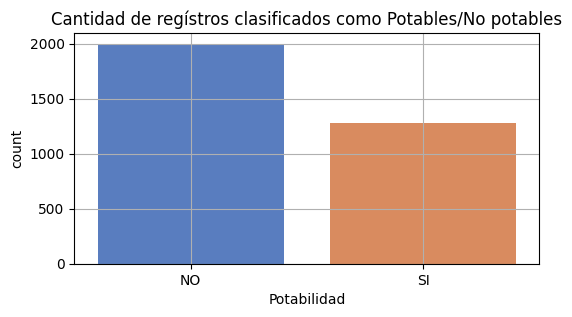

In [26]:
# Conteo de potabilidad y no potabilidad
plt.figure(figsize=(6,3))
sns.countplot(data=df,x='Potabilidad', palette = 'muted')
plt.title('Cantidad de regístros clasificados como Potables/No potables')
plt.grid()
plt.show()

In [27]:
# Porcentaje de potabilidad
potabilidad = (df[['Potabilidad']].value_counts()/len(df))*100
potabilidad

,count
Potabilidad,
NO,60.989011
SI,39.010989


Debido a que deseamos asegurar que nuestros datos sean lo suficientemente apropiados para generar un modelo que capture la realidad de la clasificación del agua como potable o no pobale, vamos a realizar un pequeño preprocesamiento de nuestros datos de manera que generemos dos datasets nuevos que contenan una variable Potable balanceada. Concretamente, generaremos un dataset balanceado a partir de subsampleo y sobremuestreo mediante la técnica SMOTE.

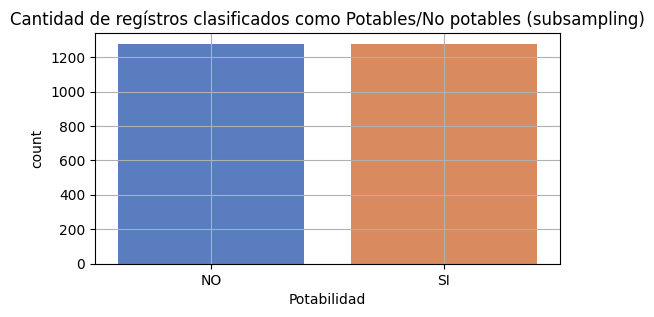

In [28]:
# Balanceo de los datos mediante submuestreo
random_seed = 77
sample_size = df['Potabilidad'].value_counts().values.min()
np.random.seed(77)

df_knn_no_enc = df_knn.drop(['Potabilidad'], axis=1)
df_knn_no_enc['Potabilidad'] = df['Potabilidad']

df_knn_sub = df_knn_no_enc.groupby('Potabilidad').apply(
    lambda x: x.sample(min( len(x), sample_size ), random_state = random_seed)
    ).reset_index(drop=True)


# Conteo de potabilidad y no potabilidad bajo el metodo de submuestreo
plt.figure(figsize=(6,3))
sns.countplot(data=df_knn_sub,x='Potabilidad', palette = 'muted')
plt.title('Cantidad de regístros clasificados como Potables/No potables (subsampling)')
plt.grid()
plt.show()

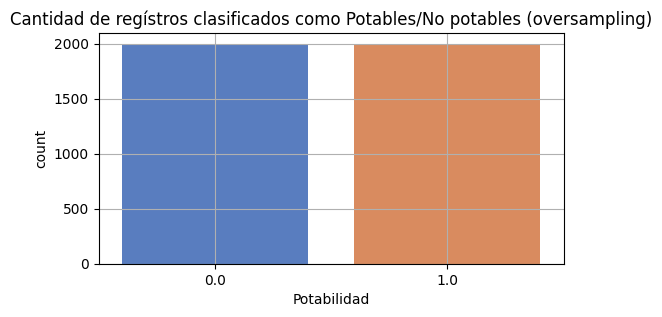

In [29]:
# Balanseo de los datos por metodo SMOTE
X = df_knn.drop(['Potabilidad'], axis=1)
y = df_knn['Potabilidad']

smote = SMOTE(sampling_strategy='auto', random_state=77)
X_resampled, y_resampled = smote.fit_resample(X, y)

df_knn_over = pd.DataFrame(X_resampled, columns=X.columns)
df_knn_over['Potabilidad'] = y_resampled


# Conteo de potabilidad y no potabilidad bajo el metodo de submuestreo
plt.figure(figsize=(6,3))
sns.countplot(data=df_knn_over,x='Potabilidad', palette = 'muted')
plt.title('Cantidad de regístros clasificados como Potables/No potables (oversampling)')
plt.grid()
plt.show()

### <!-- Subsection 2.5 -->
**<h3 id="subsection25" style="color: #003366;">2.5. Análisis bivariado y de correlación</h3>**

---
Análisis bivariado y de correlación

---

Gracias a que nuestro dataset posee solo 9 variables, nos es posible realizar  una mayor cantidad de comparaciones entre variables sin perder fácilmente el control ni el enfoque del análisis exploratorio. En la presente sección exploraremos los datos en búsqueda de patrones de relación directa entre pares de variables bien sea en forma de correlación (linealidad) o, patrones no lineales como clusters.

Para empezar, creemos un dataframe imputado sin codificación dummies o onehot.

In [30]:
# Imputación de valores por medio del algoritmo KNN
df_knn_no_enc = df_knn.drop(['Potabilidad'], axis=1)
df_knn_no_enc['Potabilidad'] = df['Potabilidad']
df_knn_no_enc.head()

,pH,Dureza,Sólidos,Cloraminas,Sulfatos,Conductividad,Carbono_orgánico,Trihalometanos,Turbidez,Potabilidad
0,7.158,204.89,20791.32,7.30,368.520,564.31,10.38,86.99,2.96,NO
1,3.720,129.42,18630.06,6.64,336.094,592.89,15.18,56.33,4.50,NO
2,8.100,224.24,19909.54,9.28,330.450,418.61,16.87,66.42,3.06,NO
3,8.320,214.37,22018.42,8.06,356.890,363.27,18.44,100.34,4.63,NO
4,9.090,181.10,17978.99,6.55,310.140,398.41,11.56,32.00,4.08,NO


Una vez tenemos de nuevo nuestra variable categórica para que podamos usarla como criterio de segmentación de datos, procedemos a realizar un pairplot que nos permita ver las relaciones bivariadas entre nuestras variables segmentadas por potabilidad.

<Figure size 1000x1000 with 0 Axes>

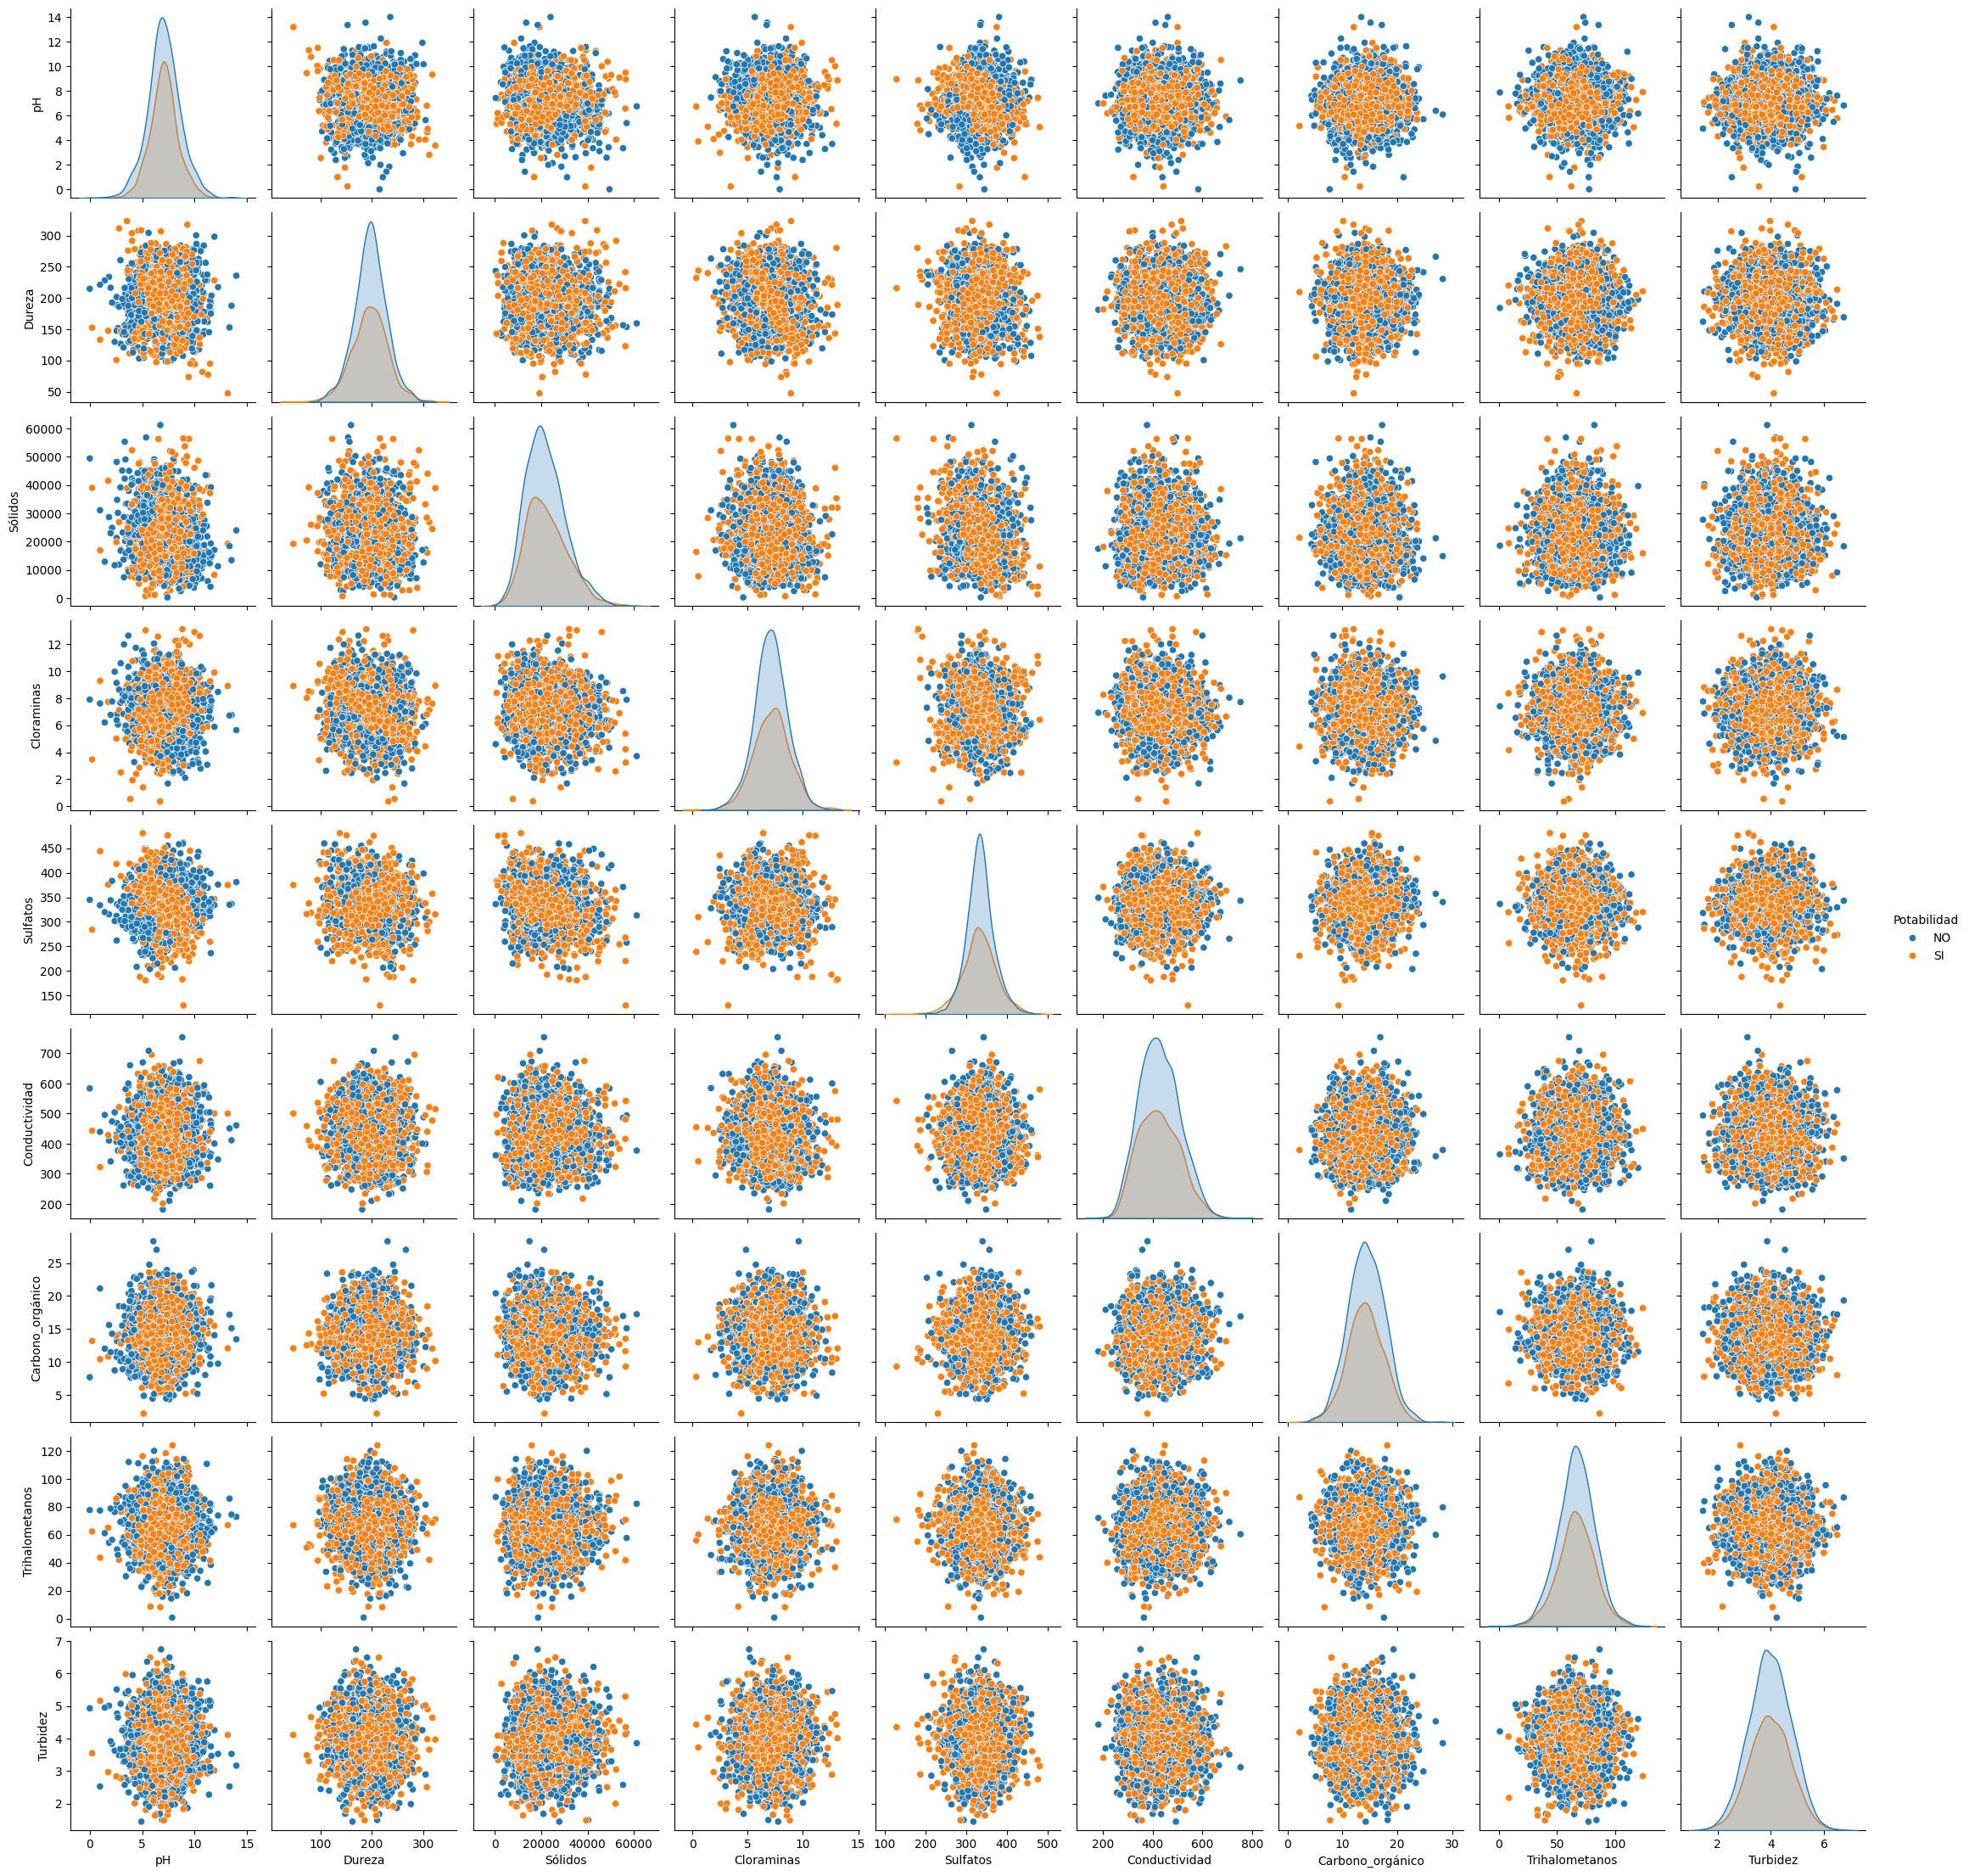

In [31]:
# Paiplot entre todas las variables usando la temporada como criterio de etiquetado
plt.figure(figsize=(10,10))
sns.pairplot(data=df_knn_no_enc, hue='Potabilidad', kind='scatter')
plt.show()

A partir de la observación del pairplot anterior, podemos hacernos una perspectiva general de como los posibles pares de variables expresan patrones dentro de los datos. Podemos observar lo siguiente:
* Ningún scatter plot entre variables refleja una relación lineal o de correlación, de hecho, cada scatter plot corresponde a un conjunto de datos que se comportan similarmente a una distribución normal bidimensional de data.
*Si observamos la diagonal del pairplot la cual nos permite ver las distribuciones de las variables, vemos que en todos los casos la distribución del agua potable es inferior a la distribución del agua no potable, lo que indica que según todas las variables, la mayor cantidad de muestras de agua corresponden a aguas no potables.

Para evidenciar cuantitativamente la falta de correlación o colinealidad entre las variables, veremos a continuación una matriz de calor que refleja el coeficiente de correlación de Pearson entre variables. Vemos que casi todos los valores son cercanos a cero.

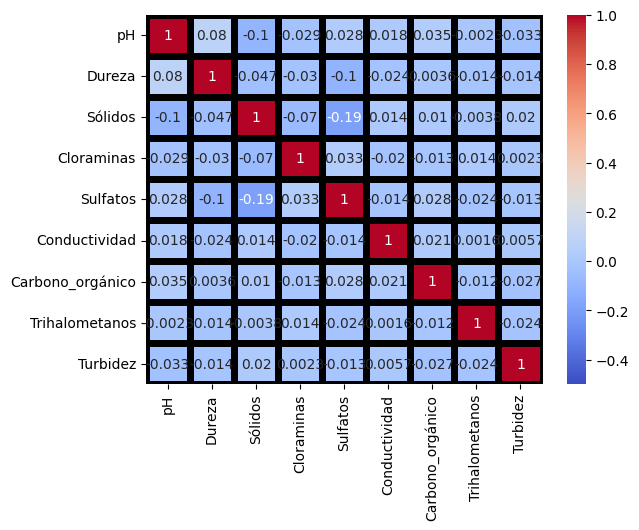

In [32]:
# Correlación entre variables
df_no_pot = df_knn.drop(['Potabilidad'],axis=1)
corr_mat = df_no_pot.corr()
sns.heatmap(corr_mat, annot=True, cmap='coolwarm', linewidths=5,
            linecolor='black', vmin=-0.5, vmax=1,
            cbar=True)
plt.show()

### <!-- Subsection 2.6 -->
**<h3 id="subsection26" style="color: #003366;">2.6. Análisis multivariado</h3>**

---
Análisis multivariado

---

El presente conjunto de datos no permite un análisis multivariado tradicional en donde podamos usar diferentes variables categóricas para realizar segmentaciones en los datos, ya que de por si solo tenemos una única variable categórica.

# <!-- Section 3 -->
**<h2 id="section3" style="color: #007ACC;">3. Escalamiento de los datos</h2>**

---
Escalamiento de los datos

---

Los métodos de escalamiento de los datos son técnicas fundamentales en el preprocesamiento de datos que buscan transformar las características de un conjunto de datos para mejorar el rendimiento y la interpretación de los modelos de análisis o aprendizaje automático. Estos métodos ajustan la escala de las variables para que todas tengan un rango comparable, lo que es especialmente útil en algoritmos que son sensibles a la magnitud de los datos. El escalamiento de los datos se vuelve necesario cuando las características tienen rangos de valores muy diferentes entre sí, como cuando una variable puede variar entre 0 y 1, mientras que otra puede oscilar entre cientos o miles. Este desbalance puede introducir sesgos no deseados en los algoritmos, afectando su capacidad de identificar patrones o tendencias relevantes.

Una de las razones escenciales por las que es necesario escalar los datos es que muchos algoritmos de machine learning, como la regresión logística, los algoritmos de clusterización o las redes neuronales, se basan en métricas de distancia o cálculos geométricos que asumen que todas las características tienen el mismo peso en el análisis. Si una característica tiene valores mucho más grandes que otra, dominará el cálculo de distancias o similares, lo que puede llevar a conclusiones incorrectas. Por ejemplo, en el caso de los modelos de clustering o de clasificación basados en distancias (como k-means o el k-vecinos más cercanos), la distancia entre puntos de datos depende directamente de las diferencias numéricas entre las variables. Sin escalamiento, una variable con mayor rango podría influir de manera desproporcionada en el resultado, distorsionando la clasificación o el agrupamiento final.

Existen diferentes métodos de escalamiento, cada uno adecuado para distintos escenarios siendo los más relevantes nombrados a continuación:

1. **Normalización (Min-Max Scaling)**: Este método ajusta los valores de las características para que se ubiquen dentro de un rango fijo, generalmente entre 0 y 1. Es útil cuando los datos siguen una distribución desconocida o no gaussiana, y es muy utilizado en redes neuronales, donde pequeñas diferencias en los valores iniciales pueden tener un gran impacto en el proceso de aprendizaje.
   
2. **Estandarización (Z-score Scaling)**: En este caso, se transforman los datos para que cada característica tenga media 0 y desviación estándar 1. Este enfoque es más robusto cuando los datos siguen una distribución gaussiana. Es común en algoritmos como los que utilizan el descenso de gradiente, como la regresión lineal y logística, porque garantiza que todas las características contribuyan de manera proporcional al cálculo de la función de costo.

3. **Escalamiento robusto (Robust Scaler)**: Esta técnica es especialmente útil cuando los datos contienen valores atípicos. A diferencia de la normalización o la estandarización, que pueden verse afectadas por los outliers, el escalamiento robusto utiliza medidas estadísticas robustas, como la mediana y el rango intercuartílico, para ajustar los valores, logrando así una mayor resistencia a la influencia de puntos extremos.

4. **Escalamiento logarítmico**: En este método, se aplica una transformación logarítmica a las características con distribuciones asimétricas o colas largas. Esto ayuda a reducir la asimetría y hace que los valores se distribuyan más uniformemente, facilitando la identificación de patrones más claros.

El escalamiento de los datos es especialmente útil para mejorar la eficiencia en algoritmos que implican la búsqueda de soluciones óptimas, como los que utilizan métodos iterativos. Sin escalamiento, los algoritmos pueden tardar más tiempo en converger o incluso quedarse atascados en soluciones subóptimas.


### <!-- Subsection 3.1 -->
**<h3 id="subsection31" style="color: #003366;">3.1. Min-Max Scaling</h3>**

---
Normalización (Min-Max Scaling)

---

El **método de escalamiento Min-Max** es una técnica de normalización que transforma los valores de una característica para que estén dentro de un rango específico, típicamente entre 0 y 1. Es uno de los métodos más simples y comunes para escalar datos, y se utiliza con frecuencia en situaciones donde el rango de los datos tiene importancia para la interpretación o cuando se desea igualar las escalas de las variables antes de aplicarlas a algoritmos sensibles a la magnitud.

El proceso de escalamiento Min-Max se basa en la siguiente fórmula matemática:

$$
X_{\text{escalado}} = \frac{X - X_{\text{min}}}{X_{\text{max}} - X_{\text{min}}}
$$

Donde:
- $ X $ es el valor original de la característica.
- $ X_{\text{min}} $ es el valor mínimo de la característica.
- $ X_{\text{max}} $ es el valor máximo de la característica.
- $ X_{\text{escalado}} $ es el valor resultante después de aplicar el escalamiento, que estará en el rango [0, 1].

De esta manera, el valor más bajo de la característica será transformado en 0 y el valor más alto será convertido en 1, con todos los valores intermedios ajustados proporcionalmente entre estos dos extremos. También es posible ajustar el rango para que los valores estén entre un mínimo y máximo diferente, por ejemplo, entre -1 y 1. La fórmula general para escalar un valor $X$ dentro de cualquier rango $[a, b]$ es:

$$
X_{\text{escalado}} = a + \frac{(X - X_{\text{min}})(b - a)}{X_{\text{max}} - X_{\text{min}}}
$$

Donde:
- $X_{\text{escalado}}$ es el valor escalado.
- $X$ es el valor original.
- $X_{\text{min}}$ es el valor mínimo del conjunto de datos.
- $X_{\text{max}}$ es el valor máximo del conjunto de datos.
- $a$ es el límite inferior del nuevo rango (en este caso, -1).
- $b$ es el límite superior del nuevo rango (en este caso, 1).

### **Ventajas del escalamiento Min-Max**

1. **Simplicidad**: El método es fácil de implementar y computacionalmente eficiente, lo que lo hace adecuado para grandes volúmenes de datos y aplicaciones donde el rendimiento es crítico.
   
2. **Mantiene la relación entre los valores originales**: A diferencia de otros métodos de escalamiento, el Min-Max conserva las relaciones relativas entre los valores originales. Esto puede ser útil cuando la distribución de los datos es importante para la interpretación.

3. **Ajuste a un rango predefinido**: Al ajustar los valores dentro de un rango definido, como $[0, 1]$, facilita la interpretación en casos específicos, como algoritmos basados en redes neuronales, donde los valores de entrada deben estar dentro de un rango reducido para acelerar el proceso de aprendizaje.

4. **Utilización en modelos basados en distancia**: Es especialmente beneficioso en algoritmos que dependen de cálculos de distancia, como **K-means clustering** o **K-nearest neighbors (K-NN)**, ya que evita que las características con grandes rangos dominen a otras con rangos más pequeños.

### **Desventajas del escalamiento Min-Max**

1. **Sensibilidad a outliers**: Uno de los principales inconvenientes de este método es que es extremadamente sensible a valores atípicos (outliers). Si los datos contienen un outlier extremo, afectará los valores mínimo y máximo, lo que distorsionará el rango completo y puede hacer que los valores intermedios estén desbalanceados o comprimidos. Por ejemplo, si una variable tiene un valor mínimo de 0, un valor máximo de 100, pero también tiene un outlier en 10,000, la mayoría de los datos serán transformados a valores cercanos a 0.

2. **No garantiza una distribución normal**: Aunque el Min-Max ajusta los valores a un rango uniforme, no transforma la distribución subyacente de los datos. Si los datos originales no siguen una distribución normal o uniforme, los valores escalados seguirán mostrando la misma forma de distribución, lo que puede no ser adecuado para ciertos algoritmos que asumen normalidad en los datos, como la regresión logística.

3. **Dependencia en el rango de datos originales**: El escalamiento Min-Max se basa en el mínimo y máximo del conjunto de datos disponibles. Si en un entorno productivo o en tiempo real aparecen nuevos valores fuera de ese rango, es necesario recalcular el escalamiento, lo que puede no ser eficiente ni práctico. Esto es particularmente problemático en aplicaciones donde se incorporan datos nuevos de forma continua.

4. **No ofrece robustez contra distribuciones no homogéneas**: Si los datos tienen diferentes rangos de valores en diferentes subconjuntos, el escalamiento Min-Max puede no manejar bien estas diferencias, ya que simplemente ajusta todo al mismo rango, lo que no siempre es óptimo en situaciones de heterogeneidad.

In [33]:
# Importación del Min-Max Scaler
from sklearn.preprocessing import MinMaxScaler

# Separamos los datos X (todas las columnas excepto 'Potabilidad') y la variable objetivo y ('Potabilidad')
X = df_knn_over.drop(columns=['Potabilidad'])
y = df_knn_over['Potabilidad']

# Escalamiento en el rango [0, 1]
scaler_0_1 = MinMaxScaler(feature_range=(0, 1))
scaled_data_0_1 = scaler_0_1.fit_transform(X)

# Escalamiento en el rango [-1, 1]
scaler_neg1_1 = MinMaxScaler(feature_range=(-1, 1))
scaled_data_neg1_1 = scaler_neg1_1.fit_transform(X)

# Crear DataFrames para los datos escalados
df_scaled_0_1 = pd.DataFrame(scaled_data_0_1, columns=X.columns)
df_scaled_neg1_1 = pd.DataFrame(scaled_data_neg1_1, columns=X.columns)

# Añadir de vuelta la columna 'Potabilidad' sin escalar
df_scaled_0_1['Potabilidad'] = y.values
df_scaled_neg1_1['Potabilidad'] = y.values

# Mostrar los resultados
print("Escalamiento en el rango [0, 1]:\n", df_scaled_0_1.head())
print("\nEscalamiento en el rango [-1, 1]:\n", df_scaled_neg1_1.head())


Escalamiento en el rango [0, 1]:
          pH    Dureza   Sólidos  Cloraminas  Sulfatos  Conductividad  \
0  0.511286  0.571149  0.336096    0.543818  0.680397       0.669447   
1  0.265714  0.297399  0.300611    0.492175  0.588285       0.719424   
2  0.578571  0.641336  0.321619    0.698748  0.572252       0.414664   
3  0.594286  0.605535  0.356244    0.603286  0.647360       0.317892   
4  0.649286  0.484856  0.289922    0.485133  0.514558       0.379341   

   Carbono_orgánico  Trihalometanos  Turbidez  Potabilidad  
0          0.313410        0.699740  0.285444          0.0  
1          0.497318        0.450998  0.576560          0.0  
2          0.562069        0.532857  0.304348          0.0  
3          0.622222        0.808048  0.601134          0.0  
4          0.358621        0.253610  0.497164          0.0  

Escalamiento en el rango [-1, 1]:
          pH    Dureza   Sólidos  Cloraminas  Sulfatos  Conductividad  \
0  0.022571  0.142298 -0.327807    0.087637  0.360793      

### <!-- Subsection 3.2 -->
**<h3 id="subsection32" style="color: #003366;">3.2. Standard Scaling</h3>**

---
Estandarización (Z-score Scaling)

---

El **método de estandarización** es una técnica de preprocesamiento que transforma los datos para que tengan una media de 0 y una desviación estándar de 1. Es una herramienta muy usada en el análisis exploratorio de datos, especialmente cuando los datos presentan diferentes escalas y distribuciones. Este método resulta útil en modelos que son sensibles a la magnitud de las características, como los algoritmos basados en distancia (tales como **K-means**, **K-nearest neighbors**), o cuando es necesario que los datos sigan una distribución normal estándar.

El proceso de estandarización se realiza utilizando la siguiente fórmula matemática:

$$
X_{\text{estandarizado}} = \frac{X - \mu}{\sigma}
$$

Donde:
- $ X $ es el valor original de la característica.
- $ \mu $ es la media de la característica.
- $ \sigma $ es la desviación estándar de la característica.
- $ X_{\text{estandarizado}} $ es el valor resultante después de aplicar la estandarización.

El resultado es que los datos quedan centrados en torno a una media de 0, con una desviación estándar igual a 1, lo que los hace más adecuados para muchos algoritmos que requieren datos normalizados o distribuidos simétricamente.

### **Ventajas de la estandarización**

1. **Escalado semi robusto**: La estandarización es menos sensible a valores atípicos (outliers) que el escalado Min-Max, ya que se basa en la media y la desviación estándar, lo que suaviza el impacto de los valores extremos, siempre que no sean extremadamente influyentes.
   
2. **Adecuado para distribuciones no uniformes**: A diferencia del escalamiento Min-Max, la estandarización ajusta los datos a una escala que puede ser útil incluso si los datos no siguen una distribución uniforme, ya que centra los datos en torno a la media, lo que permite que características con diferentes rangos se procesen de manera más equilibrada.

3. **Ideal para algoritmos basados en distancia**: Este método es útil en algoritmos que dependen de cálculos de distancia, como **SVM** o **regresión logística**, ya que estos algoritmos pueden asumir que los datos están distribuidos normalmente o requieren que las características tengan la misma escala. En conjuntos de datos con una gran variabilidad en los valores de las características, la estandarización permite que cada característica contribuya de manera equitativa al análisis, sin que aquellas con valores más altos dominen el comportamiento del modelo.

### **Desventajas de la estandarización**

1. **No limita los valores a un rango fijo**: A diferencia del escalado Min-Max, la estandarización no restringe los valores dentro de un rango específico como $[0, 1]$ o $[-1, 1]$. Esto puede hacer que sea más difícil interpretar los resultados en ciertos contextos o cuando se trabaja con modelos que prefieren entradas limitadas.

2. **Sensibilidad a valores atípicos extremos**: Aunque es menos sensible a outliers que el Min-Max, la estandarización puede seguir viéndose afectada por valores atípicos extremos, ya que estos influyen en la media y la desviación estándar, distorsionando el escalado en presencia de datos muy extremos.

3. **Asume una distribución aproximadamente normal**: Aunque no requiere una distribución exactamente normal, la estandarización asume que los datos están distribuidos de forma aproximadamente normal, lo que puede no ser cierto en algunos conjuntos de datos. Si los datos están muy sesgados o presentan distribuciones complejas, este método puede no ser el más adecuado.

4. **Dependencia en la desviación estándar de los datos**: Si los datos tienen una desviación estándar muy baja (por ejemplo, si están muy concentrados en torno a un valor), la estandarización puede generar valores extremadamente grandes o pequeños, lo que puede complicar el análisis.


In [34]:
# Importación de un escalador tipo estantarizador
from sklearn.preprocessing import StandardScaler

# Separamos los datos X (todas las columnas excepto 'Potabilidad') y la variable objetivo y ('Potabilidad')
X = df_knn_over.drop(columns=['Potabilidad'])
y = df_knn_over['Potabilidad']

# Inicializamos el escalador estándar
scaler = StandardScaler()

# Aplicamos la estandarización a las características
X_scaled = scaler.fit_transform(X)

# Convertimos el array estandarizado de nuevo a un DataFrame, manteniendo los nombres de las columnas originales
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

# Volvemos a incluir la columna 'Potabilidad' en el DataFrame estandarizado
df_knn_over_scaled = pd.concat([X_scaled_df, y.reset_index(drop=True)], axis=1)

# Visualizamos las primeras filas del DataFrame estandarizado
print(df_knn_over_scaled.head())


         pH    Dureza   Sólidos  Cloraminas  Sulfatos  Conductividad  \
0  0.061636  0.270279 -0.150402    0.111809  0.941836       1.757231   
1 -2.347205 -2.079469 -0.393841   -0.316257  0.079635       2.119331   
2  0.721650  0.872739 -0.249723    1.396005 -0.070438      -0.088746   
3  0.875794  0.565438 -0.012185    0.604732  0.632597      -0.789888   
4  1.415296 -0.470419 -0.467175   -0.374629 -0.610477      -0.344674   

   Carbono_orgánico  Trihalometanos  Turbidez  Potabilidad  
0         -1.219240        1.325724 -1.326990          0.0  
1          0.290166       -0.661581  0.717779          0.0  
2          0.821602       -0.007572 -1.194213          0.0  
3          1.315303        2.191037  0.890389          0.0  
4         -0.848178       -2.238590  0.160115          0.0  


### <!-- Subsection 3.3 -->
**<h3 id="subsection33" style="color: #003366;">3.3. Robust Scaling</h3>**

---
Escalado Robust (Robust Scaler)

---

El **método de escalado robusto** es una técnica de preprocesamiento de datos diseñada para mitigar el impacto de valores atípicos (outliers). A diferencia de la estandarización tradicional, que utiliza la media y la desviación estándar, el escalado robusto utiliza la mediana y los rangos intercuartílicos (IQR), lo que lo hace menos sensible a outliers extremos. Esto es útil cuando se tienen datos con distribuciones sesgadas o con valores atípicos que podrían distorsionar los resultados al aplicar otros métodos de escalado.

El escalado robusto transforma los datos utilizando la siguiente fórmula matemática:

$$
X_{\text{escalado}} = \frac{X - \text{mediana}(X)}{\text{IQR}(X)}
$$

Donde:
- $X$ es el valor original de la característica.
- $\text{mediana}(X)$ es la mediana de la característica.
- $\text{IQR}(X)$ es el rango intercuartílico de la característica, que se calcula como el valor del tercer cuartil (Q3) menos el valor del primer cuartil (Q1).
- $X_{\text{escalado}}$ es el valor resultante después de aplicar el escalado robusto.

Este enfoque asegura que los valores de las características se centren alrededor de la mediana y que las características estén distribuidas en función de su rango intercuartílico, lo que evita que los outliers influyan significativamente en la transformación.

### **Ventajas del escalado robusto**

1. **Robustez frente a outliers**: La principal ventaja de este método es su resistencia a los valores atípicos, ya que se basa en la mediana y el IQR, en lugar de la media y la desviación estándar, que son más sensibles a outliers extremos. Esto lo convierte en una buena opción cuando se trabaja con conjuntos de datos que contienen valores atípicos significativos.

2. **Distribución no normal**: A diferencia de la estandarización, el escalado robusto no asume que los datos sigan una distribución normal. Esto lo hace útil para conjuntos de datos con distribuciones no simétricas o que presentan sesgos importantes.

3. **Adecuado para características con rangos heterogéneos**: Este método permite que las características con diferentes escalas o distribuciones se ajusten de manera más uniforme, lo que es beneficioso en modelos que dependen de la relación entre las características, como los algoritmos basados en distancia.

4. **Aplicable en entornos productivos**: Una vez que los valores intercuartílicos se calculan, el escalado robusto puede aplicarse sin necesidad de recalibración constante, incluso en escenarios de datos en tiempo real o en producción.

### **Desventajas del escalado robusto**

1. **No restringe los valores a un rango específico**: Al igual que la estandarización, el escalado robusto no limita los valores transformados dentro de un rango predefinido como $[0, 1]$ o $[-1, 1]$. Esto puede dificultar la interpretación de los resultados o no ser adecuado para ciertos algoritmos que prefieren entradas con límites fijos.

2. **No mantiene las relaciones originales**: Dado que se basa en la mediana y el rango intercuartílico, el escalado robusto puede distorsionar las relaciones lineales entre los valores originales, lo que no siempre es deseable, especialmente en problemas donde la estructura original de los datos es importante.

3. **Menor precisión en distribuciones sin outliers**: Si el conjunto de datos no contiene valores atípicos significativos o tiene una distribución normal bien ajustada, el escalado robusto puede no ofrecer ventajas sobre la estandarización tradicional y puede perder precisión al representar los datos.


In [35]:
# Importación de un escalador tipo estantarizador robusto
from sklearn.preprocessing import RobustScaler

# Separamos los datos X (todas las columnas excepto 'Potabilidad') y la variable objetivo y ('Potabilidad')
X = df_knn_over.drop(columns=['Potabilidad'])
y = df_knn_over['Potabilidad']

# Inicializamos el escalador robusto
scaler = RobustScaler()

# Aplicamos el escalado robusto a las características
X_scaled = scaler.fit_transform(X)

# Convertimos el array escalado de nuevo a un DataFrame, manteniendo los nombres de las columnas originales
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

# Volvemos a incluir la columna 'Potabilidad' en el DataFrame escalado
df_knn_over_scaled = pd.concat([X_scaled_df, y.reset_index(drop=True)], axis=1)

# Visualizamos las primeras filas del DataFrame escalado
print(df_knn_over_scaled.head())

         pH    Dureza   Sólidos  Cloraminas  Sulfatos  Conductividad  \
0  0.063473  0.205963 -0.022141    0.082474  0.812613       1.275877   
1 -1.995210 -1.721382 -0.206193   -0.257732  0.064358       1.530892   
2  0.627545  0.700121 -0.097233    1.103093 -0.065881      -0.024181   
3  0.759281  0.448062  0.082358    0.474227  0.544242      -0.517971   
4  1.220359 -0.401583 -0.261638   -0.304124 -0.534550      -0.204422   

   Carbono_orgánico  Trihalometanos  Turbidez  Potabilidad  
0         -0.909085        1.041493 -0.970297          0.0  
1          0.234809       -0.529973  0.554455          0.0  
2          0.637554       -0.012814 -0.871287          0.0  
3          1.011703        1.725742  0.683168          0.0  
4         -0.627878       -1.776997  0.138614          0.0  


### <!-- Subsection 3.4 -->
**<h3 id="subsection34" style="color: #003366;">3.4. Robust Scaling</h3>**

---
Escalado Logarítmico (Logarithmic Scaling)

---

El **escalado logarítmico** es una técnica de preprocesamiento de datos utilizada para transformar características con distribuciones altamente asimétricas o sesgadas, especialmente cuando se tienen valores que varían en varios órdenes de magnitud. Al aplicar una transformación logarítmica, los datos se "comprimen" en un rango más manejable, lo que reduce la influencia de los valores extremadamente grandes y permite un análisis más equilibrado de las características. Este tipo de transformación es especialmente útil cuando las características presentan una distribución sesgada hacia la derecha o cuando hay valores que crecen exponencialmente.

La transformación logarítmica se realiza utilizando la siguiente fórmula:

$$
X_{\text{log}} = \log(X + \epsilon)
$$

Donde:
- $X$ es el valor original de la característica.
- $X_{\text{log}}$ es el valor resultante después de aplicar la transformación logarítmica.
- $\log$ es la función logarítmica.
- $\epsilon$ es un valor muy pequeño (generalmente cercano a $1e^{-7}$ o $1$) que se añade para evitar problemas cuando $X = 0$.

### ¿Cuándo utilizar el escalado logarítmico?

1. **Distribuciones con sesgo a la derecha**: Si los datos presentan una distribución con una cola larga hacia valores altos, la transformación logarítmica puede reducir la influencia de esos valores extremos, haciendo que la distribución sea más simétrica.

2. **Escalas exponenciales o altamente variables**: El escalado logarítmico es útil cuando los datos varían en varios órdenes de magnitud. Al comprimir los valores grandes de forma significativa y reducir la distancia entre ellos, los modelos de machine learning pueden manejar mejor las diferencias entre las características.

3. **Datos positivos con valores atípicos grandes**: Dado que los logaritmos sólo están definidos para valores positivos, esta transformación es ideal para datos que no contengan valores negativos o cercanos a cero, pero que presenten valores atípicos muy grandes.

4. **Datos con crecimiento exponencial**: Si los datos crecen exponencialmente (como ingresos de una empresa, conteos de usuarios, crecimiento poblacional, etc.), la transformación logarítmica ayuda a linealizar la relación entre los datos, facilitando su análisis en modelos lineales o basados en distancia.

### **Ventajas del escalado logarítmico**

1. **Reducción de la influencia de outliers**: La transformación logarítmica comprime los valores altos, lo que reduce el efecto de los outliers extremos en los modelos y hace que las características sean más equilibradas para su análisis.

2. **Mejor manejo de datos en varias escalas**: Cuando las características tienen rangos extremadamente amplios, la transformación logarítmica permite que los modelos de machine learning procesen mejor las diferencias entre ellas, evitando que las características más grandes dominen a las más pequeñas.

3. **Linealización de relaciones no lineales**: En algunos casos, la relación entre las características no es lineal, pero al aplicar una transformación logarítmica, es posible convertir una relación no lineal en una lineal, mejorando así el rendimiento de modelos lineales.

4. **Adecuado para distribuciones sesgadas**: La transformación logarítmica puede mejorar la simetría de las distribuciones con sesgo positivo (a la derecha), ayudando a que los datos se comporten de manera más cercana a una distribución normal.

### **Desventajas del escalado logarítmico**

1. **No aplicable a valores negativos o cero**: Los logaritmos no están definidos para valores negativos o cero, por lo que esta transformación no puede aplicarse directamente a características que contengan estos valores. En su lugar, es común añadir un valor $\epsilon$ para asegurar que todos los valores sean positivos antes de la transformación.

2. **No adecuado para datos ya simétricos**: Si los datos ya tienen una distribución aproximadamente normal o simétrica, aplicar una transformación logarítmica puede distorsionar la distribución, afectando negativamente el rendimiento del modelo.

3. **Dificultad de interpretación**: Después de aplicar la transformación logarítmica, los valores ya no corresponden directamente a las magnitudes originales, lo que puede hacer que la interpretación de los resultados sea más compleja, especialmente cuando se presentan los resultados finales a usuarios no técnicos.


In [36]:
# Escalamiento Logarítmico
X = df_knn_over.drop(columns=['Potabilidad'])
y = df_knn_over['Potabilidad']

# Aplicamos la transformación logarítmica a las características, añadiendo un pequeño valor epsilon para evitar log(0)
epsilon = 1e-7
X_log_scaled = np.log(X + epsilon)

# Convertimos el array transformado de nuevo a un DataFrame, manteniendo los nombres de las columnas originales
X_log_scaled_df = pd.DataFrame(X_log_scaled, columns=X.columns)

# Volvemos a incluir la columna 'Potabilidad' en el DataFrame transformado
df_knn_over_log_scaled = pd.concat([X_log_scaled_df, y.reset_index(drop=True)], axis=1)

# Visualizamos las primeras filas del DataFrame escalado logarítmicamente
print(df_knn_over_log_scaled.head())

         pH    Dureza   Sólidos  Cloraminas  Sulfatos  Conductividad  \
0  1.968231  5.322473  9.942291    1.987874  5.909495       6.335604   
1  1.313724  4.863063  9.832532    1.893112  5.817391       6.385009   
2  2.091864  5.412717  9.898954    2.227862  5.800455       6.036940   
3  2.118662  5.367703  9.999635    2.086914  5.877428       5.895146   
4  2.207175  5.199049  9.796959    1.879465  5.737024       5.987482   

   Carbono_orgánico  Trihalometanos  Turbidez  Potabilidad  
0          2.339881        4.465793  1.085189          0.0  
1          2.719979        4.031227  1.504077          0.0  
2          2.825537        4.195998  1.118415          0.0  
3          2.914522        4.608564  1.532557          0.0  
4          2.447551        3.465736  1.406097          0.0  


**<h2 style="color: #007ACC;">Créditos</h2>**

---

**Docente:** Nicolás Castillo Ojeda

**Universidad Pedagógica y Tecnológica de Colombia** - *Diplomado en Data Science: Aplicaciones con Machine Learning - Cohorte II - 2024*


---